# 9장. (1)주소데이터분석

## 4. 데이터 준비 및 탐색

## 4.2 분석할 커피 매장의 주소 데이터 준비하기

In [2]:
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib

In [3]:
!pip install kiwipiepy

In [4]:
import pandas as pd

CB = pd.read_csv( './9장_data/CoffeeBean.csv', encoding = 'CP949', index_col = 0, header = 0, engine = 'python')

CB.head() #작업 내용 확인용 출력

,store,address,phone
0,차병원점,서울시 강남구 논현로 566 강남차병원1층,02-538-7615
1,강남대로점,서울시 서초구 강남대로 369 1층,02-588-5778
2,청담에스점,"서울시 강남구 압구정로 461 네이처포엠빌딩B108,109호",02-548-6052
3,신사점,서울시 강남구 도산대로 126,02-548-2741
4,역삼점,"서울시 강남구 논현로 512 지상1,2층",02-569-8051


### 주소 데이터를 행정구역 주소 체계에 맞게 정리하기

In [5]:
addr = []
for address in CB.address:
    addr.append(str(address).split())
    
addr #작업 내용 확인용 출력

[['서울시', '강남구', '논현로', '566', '강남차병원1층'],
 ['서울시', '서초구', '강남대로', '369', '1층'],
 ['서울시', '강남구', '압구정로', '461', '네이처포엠빌딩B108,109호'],
 ['서울시', '강남구', '도산대로', '126'],
 ['서울시', '강남구', '논현로', '512', '지상1,2층'],
 ['서울시', '서초구', '강남대로', '213', '24호', '지하1층'],
 ['서울시', '강남구', '삼성로', '716', 'LEE76빌딩2층'],
 ['서울', '서초구', '반포동', '736-17', 'P빌딩', '2층'],
 ['서울시', '강남구', '언주로', '30길', '10,112', '현대비젼21', '112호'],
 ['서울시', '강남구', '선릉로', '749', '1,2층'],
 ['서울시', '강남구', '도산대로49길', '13', '1층', '17,18호'],
 ['서울시', '서초구', '강남대로', '51길', '1', '511', 'TOWER', '1층'],
 ['서울시', '강남구', '논현', '231-13호', '팍스타워지하1층'],
 ['서울', '강남구', '테헤란로87길', '46', '지하', '2층'],
 ['서울시', '강남구', '영동대로', '511', '트레이드타워', '지하1층'],
 ['서울시', '강남구', '영동대로', '607', '1,2층'],
 ['서울시', '송파구', '석촌호수로', '118', '1층'],
 ['서울시', '서초구', '서초동', '1685-8호', '101~2호,113~4호,121호'],
 ['서울시', '강남구', '논현로', '717', '1층'],
 ['서울시', '서초구', '서초대로74길', '11', '지하2층'],
 ['서울시', '서초구', '서초대로74길', '4', '삼성생명보험서초타워내지하1층'],
 ['서울특별시', '서초구', '방배중앙로', '187'],
 ['서울시',

In [6]:
addr2 = []
for i in range(len(addr)):    
    if addr[i][0] == "서울": addr[i][0] = "서울특별시"
    elif addr[i][0] == "서울시": addr[i][0] = "서울특별시"
    elif addr[i][0] == "부산시": addr[i][0] = "부산광역시"
    elif addr[i][0] == "인천": addr[i][0] = "인천광역시"
    elif addr[i][0] == "광주": addr[i][0] = "광주광역시"
    elif addr[i][0] == "대전시": addr[i][0] = "대전광역시"
    elif addr[i][0] == "울산시": addr[i][0] = "울산광역시"
    elif addr[i][0] == "세종시": addr[i][0] = "세종특별자치시"
    elif addr[i][0] == "경기": addr[i][0] = "경기도"
    elif addr[i][0] == "충북": addr[i][0] = "충청북도"
    elif addr[i][0] == "충남": addr[i][0] = "충청남도"
    elif addr[i][0] == "전북": addr[i][0] = "전북특별자치도"
    elif addr[i][0] == "전남": addr[i][0] = "전라남도"
    elif addr[i][0] == "경북": addr[i][0] = "경상북도"
    elif addr[i][0] == "경남": addr[i][0] = "경상남도"
    elif addr[i][0] == "제주": addr[i][0] = "제주특별자치도"
    elif addr[i][0] == "제주도": addr[i][0] = "제주특별자치도"
    elif addr[i][0] == "제주시": addr[i][0] = "제주특별자치도"
    addr2.append(' '.join(addr[i]))
    
addr2 #작업 내용 확인용 출력

['서울특별시 강남구 논현로 566 강남차병원1층',
 '서울특별시 서초구 강남대로 369 1층',
 '서울특별시 강남구 압구정로 461 네이처포엠빌딩B108,109호',
 '서울특별시 강남구 도산대로 126',
 '서울특별시 강남구 논현로 512 지상1,2층',
 '서울특별시 서초구 강남대로 213 24호 지하1층',
 '서울특별시 강남구 삼성로 716 LEE76빌딩2층',
 '서울특별시 서초구 반포동 736-17 P빌딩 2층',
 '서울특별시 강남구 언주로 30길 10,112 현대비젼21 112호',
 '서울특별시 강남구 선릉로 749 1,2층',
 '서울특별시 강남구 도산대로49길 13 1층 17,18호',
 '서울특별시 서초구 강남대로 51길 1 511 TOWER 1층',
 '서울특별시 강남구 논현 231-13호 팍스타워지하1층',
 '서울특별시 강남구 테헤란로87길 46 지하 2층',
 '서울특별시 강남구 영동대로 511 트레이드타워 지하1층',
 '서울특별시 강남구 영동대로 607 1,2층',
 '서울특별시 송파구 석촌호수로 118 1층',
 '서울특별시 서초구 서초동 1685-8호 101~2호,113~4호,121호',
 '서울특별시 강남구 논현로 717 1층',
 '서울특별시 서초구 서초대로74길 11 지하2층',
 '서울특별시 서초구 서초대로74길 4 삼성생명보험서초타워내지하1층',
 '서울특별시 서초구 방배중앙로 187',
 '서울특별시 강남구 테헤란로 20길 10 쓰리엠타워1층',
 '서울특별시 강남구 테헤란로 70길 12 1층',
 '서울특별시 강남구 봉은사로 628 엘슨빌딩1층',
 '서울특별시 송파구 오금로 11길 7',
 '서울특별시 강남구 논현로 38길 42 418호',
 '서울특별시 서초구 서초중앙로 43 로얄타워1층',
 '서울특별시 강남구 테헤란로4길 28 826-28호 1층',
 '서울특별시 강남구 테헤란로87길 36 공항타워 1층',
 '서울특별시 강남구 도산대로 67길 7,파크빌딩 1층',
 '서울특별시 종로구 서린동 13

In [7]:
# 주소 데이터를 행정구역 주소 체계에 맞게 정리
addr2 = pd.DataFrame(addr2, columns = ['address2'])
addr2.head()

,address2
0,서울특별시 강남구 논현로 566 강남차병원1층
1,서울특별시 서초구 강남대로 369 1층
2,"서울특별시 강남구 압구정로 461 네이처포엠빌딩B108,109호"
3,서울특별시 강남구 도산대로 126
4,"서울특별시 강남구 논현로 512 지상1,2층"


In [8]:
# 주소 데이터를 행정구역 주소 체계에 맞게 정리
CB2 = pd.concat([CB, addr2], axis = 1 )
CB2.head() #작업 내용 확인용 출력

,store,address,phone,address2
0,차병원점,서울시 강남구 논현로 566 강남차병원1층,02-538-7615,서울특별시 강남구 논현로 566 강남차병원1층
1,강남대로점,서울시 서초구 강남대로 369 1층,02-588-5778,서울특별시 서초구 강남대로 369 1층
2,청담에스점,"서울시 강남구 압구정로 461 네이처포엠빌딩B108,109호",02-548-6052,"서울특별시 강남구 압구정로 461 네이처포엠빌딩B108,109호"
3,신사점,서울시 강남구 도산대로 126,02-548-2741,서울특별시 강남구 도산대로 126
4,역삼점,"서울시 강남구 논현로 512 지상1,2층",02-569-8051,"서울특별시 강남구 논현로 512 지상1,2층"


In [9]:
CB2.to_csv('9장_data/CoffeeBean_2.csv', encoding = 'CP949', index = False)

## 5. 분석 모델 구축 및 시각화

### 5.1 지도 객체 생성하기

In [10]:
! pip install folium

In [11]:
import folium

In [12]:
# 숭례문
map_osm = folium.Map(location = [37.56018, 126.9753], zoom_start = 18)

In [13]:
map_osm.save('9장_data/map_1209.html')

In [14]:
# 옵션 - 'CartoDB dark_matter'블랙테마 / 'Stamen Watercolor'물감느낌 / 'Stamen Terrain'산지형 강조 등
map_op = folium.Map(location=[37.56017, 126.9753], zoom_start=10, tiles='CartoDB dark_matter')

# 마커 옵션
folium.Marker([37.56017, 126.9753], popup='남대문', icon=folium.Icon(color='purple', icon="cloud")).add_to(map_op)
map_op.save('9장_data/map_1.html')

### 5.2 지도 객체에 커피 매장 위치 표시하기

#### - https://www.geoservice.co.kr/ 에 접속하여 매장주소에 대한 위도/경도를 구하여 저장한 "CB_geo.csv" 파일을 준비한다.

In [15]:
CB_geoData = pd.read_csv('9장_data/CB_geo.csv', encoding = 'utf8', engine = 'python')

In [16]:
map_CB = folium.Map(location = [37.560284, 126.975334], zoom_start = 15)

In [17]:
#iterrows는 데이터프레임의 행들을 하나씩 조개서 반환해준다.
#
for i, store in CB_geoData.iterrows():
    folium.Marker( location = [store['_Y'], store['_X']], popup = store['store'], 
                  icon = folium.Icon(color = 'red', icon = 'ok-sign')).add_to(map_CB)

In [18]:
map_CB.save('9장_data/map_CB.html')

## HOLLYS실습
#### iterrows는 데이터프레임의 행들을 하나씩 조개서 반환해준다.
#### _GC_TYPE은 주로 지오코딩(주소-좌표 변환) 결과의 정확도 수준을 나타내는 코드입니다.
####  좌표가 얼마나 신뢰할 수 있는지 분류하는 데 사용됩니다.
#### 정 (Exact): 입력한 주소와 정확히 일치하는 위치의 좌표입니다.
#### 유 (Similar): 입력한 주소와 완전히 일치하진 않지만, 유사한 주소(도로명, 건물명 등)의 좌표입니다.

In [19]:
hollys1 = pd.read_csv('9장_data/hollys1.csv', encoding = 'utf8', engine = 'python')

In [20]:
#할리스 위치
map_ho = folium.Map(location = [37.550971, 126.960395], zoom_start = 15, tiles='Esri WorldImagery')
for i, store in hollys1.iterrows():
    folium.Marker( location = [store['_Y'], store['_X']], popup = store['store'], 
                  icon = folium.Icon(color = 'pink',
                                     #커피 아이콘을 사용하기 위해 prefix=fa 필요 
                                     icon = 'coffee', prefix='fa', 
                                     #아이콘 클릭하면 어느지점인지 보여주기
                                     tooltip = store['store'])).add_to(map_ho)

In [21]:
map_ho.save('9장_data/map_ho.html')

# 9장. (2)행정구역데이터분석

## 4. 데이터 준비 및 탐색

### 4.1 공공보건의료기관 현황 데이터 준비하기

In [22]:
import pandas as pd
pd.set_option('mode.chained_assignment', None)

import numpy as np

data = pd.read_csv('9장_data/공공보건의료기관현황.csv', index_col = 0, encoding = 'CP949', engine = 'python')
data.head(1) #작업 확인용 출력

,병원 명,설립형태,근거 법령,관계 행정기관,관계 공공단체,심평원 요양기관번호,종별구분,병상수,소재지 우편번호,주소,홈페이지,대표전화,FAX,비고
연번,,,,,,,,,,,,,,
1,강원도 재활병원,시도립,강원도재활병원설치및운영에관한조례,강원도,해당없음,32200641,병원,165,24227,강원도 춘천시 충열로 142번길 24-16,www.grh.or.kr,033-248-7700,033-248-7723,NaN


In [23]:
# 주소에서 시도, 군구 정보 분리
addr = pd.DataFrame( data['주소'].apply(lambda v: v.split()[:2]).tolist(), columns = ('시도', '군구'))

addr.head() #작업 확인용 출력

,시도,군구
0,강원도,춘천시
1,강원도,삼척시
2,강원도,영월군
3,강원도,원주시
4,강원도,강릉시


### - 시도 데이터 보정

In [24]:
addr['시도'].unique()

array(['강원도', '경기도', '경기', '경남', '창원시', '경상남도', '경상북도', '경산시', '경북',
       '인천광역시', '대구광역시', '전라남도', '대전광역시', '광주광역시', '제주특별자치도', '부산광역시',
       '전라북도', '충북', '서울특별시', '서울시', '부산특별시', '대전시', '충남', '전남', '충청남도',
       '울산광역시', '전북', '천안시', '충청북도'], dtype=object)

In [25]:
addr[addr['시도'] == '창원시']

,시도,군구
27,창원시,의창구
31,창원시,마산합포구3.15대로


In [26]:
addr.iloc[27] = ['경상남도', '창원시']
addr.iloc[31] = ['경상남도', '창원시']

In [27]:
addr.iloc[27] #작업 결과 확인

시도    경상남도
군구     창원시
Name: 27, dtype: object

In [28]:
addr.iloc[31] #작업 결과 확인

시도    경상남도
군구     창원시
Name: 31, dtype: object

In [29]:
addr[addr['시도'] == '경산시']

,시도,군구
47,경산시,경안로


In [30]:
addr.iloc[47] = ['경상북도', '경산시']

In [31]:
addr[addr['시도'] == '천안시']

,시도,군구
209,천안시,동남구
210,천안시,동남구


In [32]:
addr.iloc[209] = ['충청남도', '천안시']
addr.iloc[210] = ['충청남도', '천안시']

In [33]:
addr['시도'].unique()

array(['강원도', '경기도', '경기', '경남', '경상남도', '경상북도', '경북', '인천광역시', '대구광역시',
       '전라남도', '대전광역시', '광주광역시', '제주특별자치도', '부산광역시', '전라북도', '충북',
       '서울특별시', '서울시', '부산특별시', '대전시', '충남', '전남', '충청남도', '울산광역시', '전북',
       '충청북도'], dtype=object)

In [34]:
addr_aliases = { '경기':'경기도', '경남':'경상남도', '경북':'경상북도',
                '충북':'충청북도', '서울시':'서울특별시', '부산특별시':'부산광역시', 
                '대전시':'대전광역시', '충남':'충청남도', '전남':'전라남도', 
                '전북':'전북특별자치도', '전라북도':'전북특별자치도','강원도':'강원특별자치도'}

In [35]:
# .get(v, v) 사전에 현 시도명이 있으면 그 값을 치환하고 없다면, 원래 그 값을 사용해라(사전에 없으면 표준어인 상태)
addr['시도'] = addr['시도'].apply(lambda v: addr_aliases.get(v, v))

In [36]:
addr['시도'].unique()

array(['강원특별자치도', '경기도', '경상남도', '경상북도', '인천광역시', '대구광역시', '전라남도',
       '대전광역시', '광주광역시', '제주특별자치도', '부산광역시', '전북특별자치도', '충청북도', '서울특별시',
       '충청남도', '울산광역시'], dtype=object)

### - 군구 데이터 보정

In [37]:
addr['군구'].unique()

array(['춘천시', '삼척시', '영월군', '원주시', '강릉시', '속초시', '정선군', '수원시', '이천시',
       '안성시', '의정부시', '포천시', '파주시', '용인시', '평택시', '시흥시', '여주시', '남양주시',
       '동두천시', '안산시', '부천시', '통영시', '사천시', '창원시', '김해시', '양산시', '거창군',
       '남해군', '의령군', '포항시', '김천시', '안동시', '울진군', '경주시', '구미시', '영주시',
       '상주시', '문경시', '경산시', '의성군', '청도군', '고령군', '칠곡군', '봉화군', '울릉군',
       '부평구', '북구', '순천시', '대덕구', '태백시', '동해시', '화성시', '광산구', '남구', '중구',
       '아란13길', '서구', '전주시', '진주시', '청주시', '종로구', '성남시', '동구', '화순군',
       '강동구', '사상구', '달서구', '해운대구', '유성구', '가평군', '양주시', '고양시', '홍천군',
       '양구군', '청원군', '계룡시', '논산시', '함평군', '양평군', '수성구', '달성군', '연수구',
       '노원구', '기장군', '공주시', '강북구', '광진구', '나주시', '창녕군', '목포시', '고흥군',
       '연제구', '동매로', '서초구', '은평구', '중랑구', '강남구', '동작구', '동대문구', '양천구',
       '성동구', '송파구', '울주군', '계양구', '옹진군', '보성군', '광양시', '영광군', '무안군',
       '진도군', '강진군', '곡성군', '여수시', '신안군', '장성군', '완주군', '부안군', '정읍시',
       '남원시', '군산시', '고창군', '진안군', '제주시', '서귀포시', '천안시', '보령시', '서산시',
       '서천

In [38]:
addr[addr['군구'] == '아란13길']

,시도,군구
75,제주특별자치도,아란13길


In [39]:
addr.iloc[75] = ['제주특별자치도', '제주시']
addr.loc[75,'시도']

'제주특별자치도'

### 행정구역별 공공보건의료기관의 수 구하기

In [40]:
addr['시도군구'] = addr.apply(lambda r: r['시도'] + ' ' + r['군구'], axis = 1)
addr.head(20) #작업 확인용 출력

,시도,군구,시도군구
0,강원특별자치도,춘천시,강원특별자치도 춘천시
1,강원특별자치도,삼척시,강원특별자치도 삼척시
2,강원특별자치도,영월군,강원특별자치도 영월군
3,강원특별자치도,원주시,강원특별자치도 원주시
4,강원특별자치도,강릉시,강원특별자치도 강릉시
5,강원특별자치도,속초시,강원특별자치도 속초시
6,강원특별자치도,춘천시,강원특별자치도 춘천시
7,강원특별자치도,강릉시,강원특별자치도 강릉시
8,강원특별자치도,정선군,강원특별자치도 정선군
9,경기도,수원시,경기도 수원시


In [41]:
addr['count'] = 0
addr.head(20) #작업 확인용 출력

,시도,군구,시도군구,count
0,강원특별자치도,춘천시,강원특별자치도 춘천시,0
1,강원특별자치도,삼척시,강원특별자치도 삼척시,0
2,강원특별자치도,영월군,강원특별자치도 영월군,0
3,강원특별자치도,원주시,강원특별자치도 원주시,0
4,강원특별자치도,강릉시,강원특별자치도 강릉시,0
5,강원특별자치도,속초시,강원특별자치도 속초시,0
6,강원특별자치도,춘천시,강원특별자치도 춘천시,0
7,강원특별자치도,강릉시,강원특별자치도 강릉시,0
8,강원특별자치도,정선군,강원특별자치도 정선군,0
9,경기도,수원시,경기도 수원시,0


In [42]:
# as_index = False -> groupby는 그룹 컬럼을 인덱스로 삼는데 일반 인덱스를 사용하겠다는 의미
addr_group = pd.DataFrame( addr.groupby(['시도', '군구', '시도군구'], as_index = False).count())
addr_group.head(20) #작업 확인용 출력

,시도,군구,시도군구,count
0,강원특별자치도,강릉시,강원특별자치도 강릉시,4
1,강원특별자치도,동해시,강원특별자치도 동해시,1
2,강원특별자치도,삼척시,강원특별자치도 삼척시,1
3,강원특별자치도,속초시,강원특별자치도 속초시,1
4,강원특별자치도,양구군,강원특별자치도 양구군,1
5,강원특별자치도,영월군,강원특별자치도 영월군,1
6,강원특별자치도,원주시,강원특별자치도 원주시,2
7,강원특별자치도,정선군,강원특별자치도 정선군,2
8,강원특별자치도,춘천시,강원특별자치도 춘천시,5
9,강원특별자치도,태백시,강원특별자치도 태백시,1


In [43]:
# .loc[] 로 특정 지역만 바로 선택하기 쉬워짐
addr_group = addr_group.set_index("시도군구")
addr_group.head() #작업 확인용 출력

,시도,군구,count
시도군구,,,
강원특별자치도 강릉시,강원특별자치도,강릉시,4
강원특별자치도 동해시,강원특별자치도,동해시,1
강원특별자치도 삼척시,강원특별자치도,삼척시,1
강원특별자치도 속초시,강원특별자치도,속초시,1
강원특별자치도 양구군,강원특별자치도,양구군,1


### 4.2 행정구역별 인구수 데이터 준비하기

In [44]:
population = pd.read_excel('9장_data/행정구역_시군구_별__성별_인구수_2.xlsx')
population.head() #작업 확인용 출력

,행정구역(시군구)별(1),행정구역(시군구)별(2),총인구수 (명),남자인구수 (명),여자인구수 (명)
0,전국,합계,51111158,25432356,25678802
1,서울특별시,소계,9299701,4480849,4818852
2,서울특별시,종로구,136798,65539,71259
3,서울특별시,중구,117718,56484,61234
4,서울특별시,용산구,201746,95984,105762


In [45]:
#컬럼명 변경
population = population.rename(columns = {'행정구역(시군구)별(1)': '시도', '행정구역(시군구)별(2)': '군구'})
population.head() #작업 확인용 출력

,시도,군구,총인구수 (명),남자인구수 (명),여자인구수 (명)
0,전국,합계,51111158,25432356,25678802
1,서울특별시,소계,9299701,4480849,4818852
2,서울특별시,종로구,136798,65539,71259
3,서울특별시,중구,117718,56484,61234
4,서울특별시,용산구,201746,95984,105762


In [46]:
# 군구 컬럼의 앞뒤 공백 지우기
population['군구'] = population['군구'].str.strip()

In [47]:
population['시도군구'] = population.apply(lambda r: r['시도'] + ' ' + r['군구'], axis = 1)
population.head() #작업 확인용 출력

,시도,군구,총인구수 (명),남자인구수 (명),여자인구수 (명),시도군구
0,전국,합계,51111158,25432356,25678802,전국 합계
1,서울특별시,소계,9299701,4480849,4818852,서울특별시 소계
2,서울특별시,종로구,136798,65539,71259,서울특별시 종로구
3,서울특별시,중구,117718,56484,61234,서울특별시 중구
4,서울특별시,용산구,201746,95984,105762,서울특별시 용산구


In [48]:
population = population[population.군구 != '합계']
population = population[population.군구 != '소계']

In [49]:
population = population.set_index("시도군구")
population.head() #작업 확인용 출력

,시도,군구,총인구수 (명),남자인구수 (명),여자인구수 (명)
시도군구,,,,,
서울특별시 종로구,서울특별시,종로구,136798,65539,71259
서울특별시 중구,서울특별시,중구,117718,56484,61234
서울특별시 용산구,서울특별시,용산구,201746,95984,105762
서울특별시 성동구,서울특별시,성동구,274695,132585,142110
서울특별시 광진구,서울특별시,광진구,330933,158412,172521


In [50]:
addr_population_merge = pd.merge(addr_group,population, how = 'inner', left_index = True, right_index = True)
addr_population_merge.head() #작업 확인용 출력

,시도_x,군구_x,count,시도_y,군구_y,총인구수 (명),남자인구수 (명),여자인구수 (명)
시도군구,,,,,,,,
강원특별자치도 강릉시,강원특별자치도,강릉시,4,강원특별자치도,강릉시,205966,101986,103980
강원특별자치도 동해시,강원특별자치도,동해시,1,강원특별자치도,동해시,86225,43776,42449
강원특별자치도 삼척시,강원특별자치도,삼척시,1,강원특별자치도,삼척시,60307,30786,29521
강원특별자치도 속초시,강원특별자치도,속초시,1,강원특별자치도,속초시,79586,39365,40221
강원특별자치도 양구군,강원특별자치도,양구군,1,강원특별자치도,양구군,20373,10697,9676


In [51]:
local_MC_Population = addr_population_merge[ ['시도_x', '군구_x','count', '총인구수 (명)']]
local_MC_Population.head() #작업 확인용 출력

,시도_x,군구_x,count,총인구수 (명)
시도군구,,,,
강원특별자치도 강릉시,강원특별자치도,강릉시,4,205966
강원특별자치도 동해시,강원특별자치도,동해시,1,86225
강원특별자치도 삼척시,강원특별자치도,삼척시,1,60307
강원특별자치도 속초시,강원특별자치도,속초시,1,79586
강원특별자치도 양구군,강원특별자치도,양구군,1,20373


In [52]:
#컬럼 이름 변경
local_MC_Population = local_MC_Population.rename(columns = {'시도_x':'시도', '군구_x': '군구','총인구수 (명)': '인구수'})
MC_count = local_MC_Population['count']
local_MC_Population['MC_ratio'] = MC_count.div(local_MC_Population['인구수'], axis = 0)*100000

local_MC_Population.head() #작업 확인용 출력

,시도,군구,count,인구수,MC_ratio
시도군구,,,,,
강원특별자치도 강릉시,강원특별자치도,강릉시,4,205966,1.942068
강원특별자치도 동해시,강원특별자치도,동해시,1,86225,1.159756
강원특별자치도 삼척시,강원특별자치도,삼척시,1,60307,1.658182
강원특별자치도 속초시,강원특별자치도,속초시,1,79586,1.256502
강원특별자치도 양구군,강원특별자치도,양구군,1,20373,4.908457


## 5. 분석 모델 구축 및 시각화

### 5.1 바 차트 그리기

In [53]:
from matplotlib import pyplot as plt
from matplotlib import rcParams, style
style.use('ggplot')

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties( fname = "c:/Windows/Fonts/malgun.ttf").get_name()
rc('font', family = font_name)

### 행정구역별 공공보건의료기관 수 바 차트

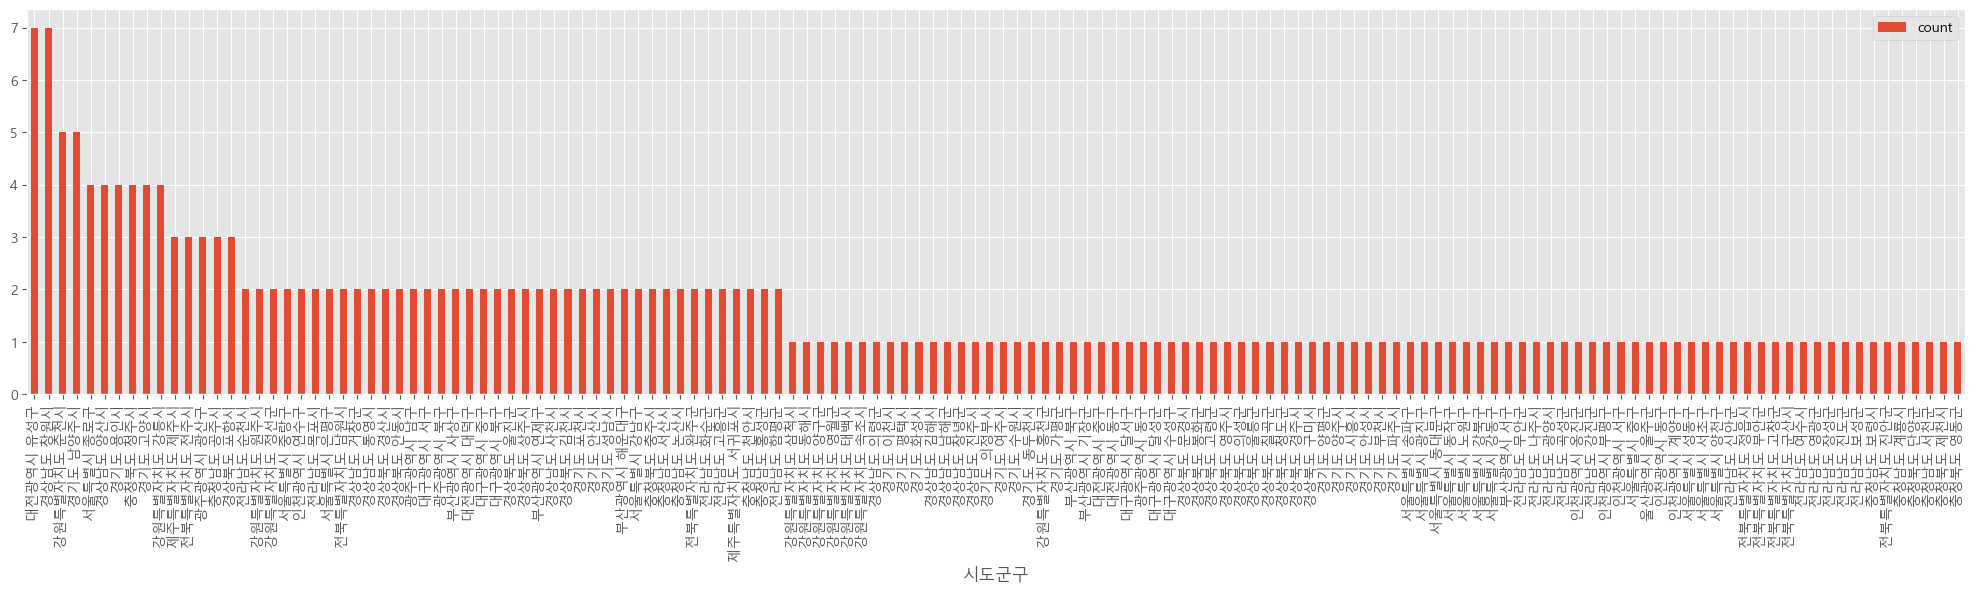

In [54]:
MC_ratio = local_MC_Population[['count']]
MC_ratio = MC_ratio.sort_values('count', ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
MC_ratio.plot(kind = 'bar', rot = 90)
plt.show()

### 행정구역별로 인구수 대비 공공보건의료기관 비율 바 차트

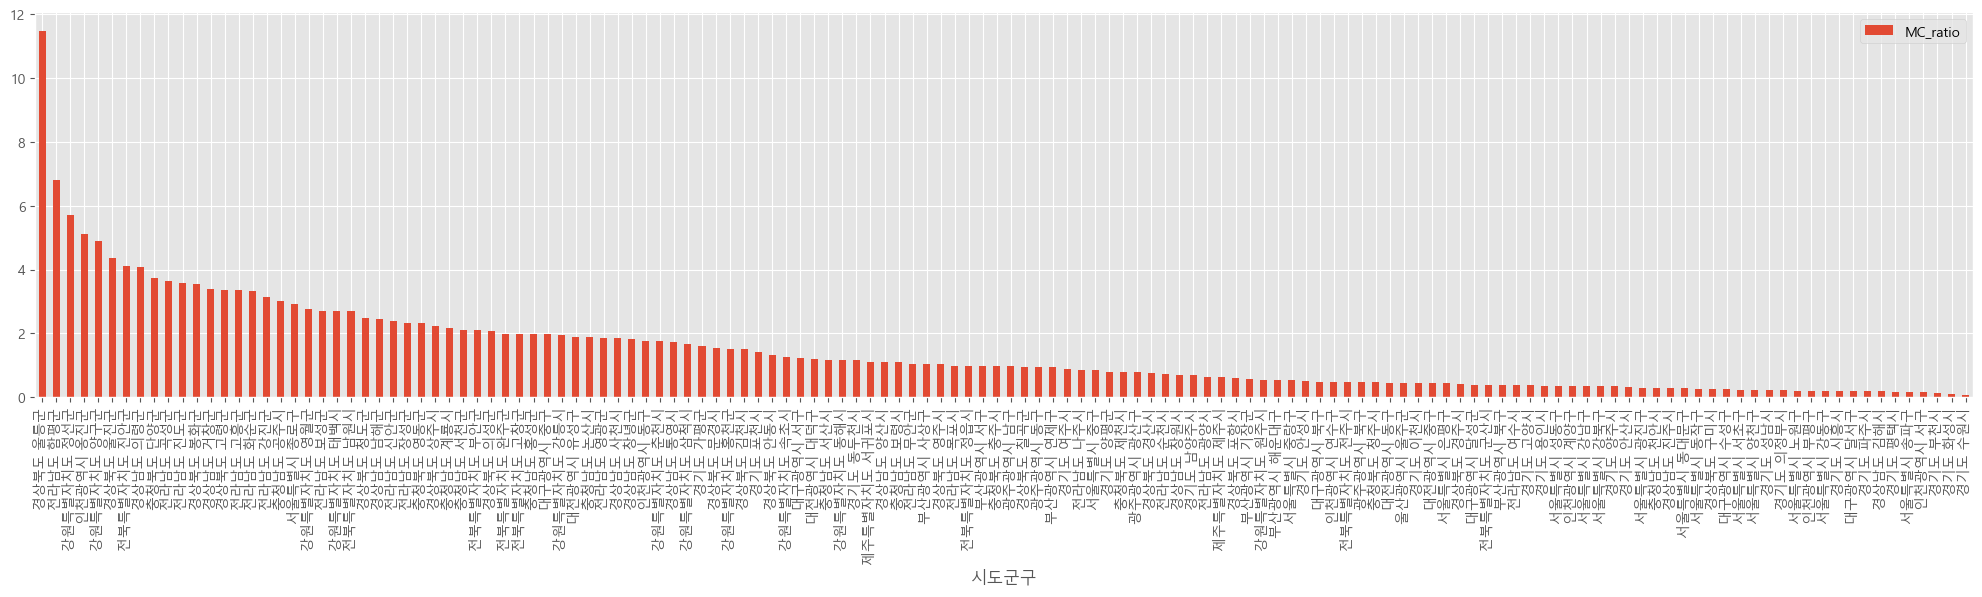

In [55]:
MC_ratio = local_MC_Population[['MC_ratio']]
MC_ratio = MC_ratio.sort_values('MC_ratio', ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
MC_ratio.plot(kind = 'bar', rot = 90)
plt.show()

## 5.2 블록맵으로 시각화하기

### 1. 데이터 준비하기

In [56]:
import os
path = os.getcwd()

In [57]:
data_draw_korea = pd.read_csv(path+'\\9장_data\\data_draw_korea.csv', index_col = 0, encoding = 'UTF-8', engine = 'python')
data_draw_korea.head(20) #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원도,강릉시
1,25589,고성(강원),9,0,664.19,강원도,고성군
2,86747,동해,11,5,180.01,강원도,동해시
3,63986,삼척,11,8,1185.80,강원도,삼척시
4,76733,속초,9,1,105.25,강원도,속초시
5,20809,양구,8,0,700.80,강원도,양구군
6,24551,양양,10,2,628.68,강원도,양양군
7,34966,영월,10,8,1127.36,강원도,영월군
8,313851,원주,10,7,867.30,강원도,원주시
9,29260,인제,9,2,1646.08,강원도,인제군


In [58]:
#2023년 6월 이후에 변경된 행정구역명으로 수정하기
addr_aliases = { '강원도':'강원특별자치도', '전라북도':'전북특별자치도'}
data_draw_korea['광역시도'] = data_draw_korea['광역시도'].apply(lambda v: addr_aliases.get(v, v))
data_draw_korea.head() #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
1,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
2,86747,동해,11,5,180.01,강원특별자치도,동해시
3,63986,삼척,11,8,1185.80,강원특별자치도,삼척시
4,76733,속초,9,1,105.25,강원특별자치도,속초시


### 2. 행정구역 이름 매핑하기

In [59]:
data_draw_korea['시도군구'] = data_draw_korea.apply(lambda r: r['광역시도'] + ' ' + r['행정구역'], axis = 1)

In [60]:
data_draw_korea = data_draw_korea.set_index("시도군구")

data_draw_korea.head() #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
시도군구,,,,,,,
강원특별자치도 강릉시,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
강원특별자치도 고성군,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
강원특별자치도 동해시,86747,동해,11,5,180.01,강원특별자치도,동해시
강원특별자치도 삼척시,63986,삼척,11,8,1185.80,강원특별자치도,삼척시
강원특별자치도 속초시,76733,속초,9,1,105.25,강원특별자치도,속초시


In [61]:
data_draw_korea_MC_Population_all = pd.merge(data_draw_korea,local_MC_Population, how = 'outer', 
                                             left_index = True, right_index = True)
data_draw_korea_MC_Population_all.head()

,인구수_x,shortName,x,y,면적,광역시도,행정구역,시도,군구,count,인구수_y,MC_ratio
시도군구,,,,,,,,,,,,
강원특별자치도 강릉시,202520,강릉,11,4,1040.07,강원특별자치도,강릉시,강원특별자치도,강릉시,4.0,205966.0,1.942068
강원특별자치도 고성군,25589,고성(강원),9,0,664.19,강원특별자치도,고성군,NaN,NaN,NaN,NaN,NaN
강원특별자치도 동해시,86747,동해,11,5,180.01,강원특별자치도,동해시,강원특별자치도,동해시,1.0,86225.0,1.159756
강원특별자치도 삼척시,63986,삼척,11,8,1185.80,강원특별자치도,삼척시,강원특별자치도,삼척시,1.0,60307.0,1.658182
강원특별자치도 속초시,76733,속초,9,1,105.25,강원특별자치도,속초시,강원특별자치도,속초시,1.0,79586.0,1.256502


### 3. 블록맵으로 시각화하기

In [62]:
BORDER_LINES = [
    [(3, 2), (5, 2), (5, 3), (9, 3), (9, 1)], # 인천
    [ (2, 5), (3, 5), (3, 4), (8, 4), (8, 7), (7, 7), (7, 9), (4, 9),
    (4, 7), (1, 7)], # 서울
    [(1, 6), (1, 9), (3, 9), (3, 10), (8, 10), (8, 9),
    (9, 9), (9, 8), (10, 8), (10, 5), (9, 5), (9, 3)], # 경기도
    [(9, 12), (9, 10), (8, 10)], # 강원도
    [(10, 5), (11, 5), (11, 4), (12, 4), (12, 5), (13, 5),
    (13, 4), (14, 4), (14, 2)], # 충청남도
    [(11, 5), (12, 5), (12, 6), (15, 6), (15, 7), (13, 7),
    (13, 8), (11, 8), (11, 9), (10, 9), (10, 8)], # 충청북도
    [(14, 4), (15, 4), (15, 6)], # 대전시
    [(14, 7), (14, 9), (13, 9), (13, 11), (13, 13)], # 경상북도
    [(14, 8), (16, 8), (16, 10), (15, 10),
    (15, 11), (14, 11), (14, 12), (13, 12)], # 대구시
    [(15, 11), (16, 11), (16, 13)], # 울산시
    [(17, 1), (17, 3), (18, 3), (18, 6), (15, 6)], # 전라북도
    [ (19, 2), (19, 4), (21, 4), (21, 3), (22, 3), (22, 2), (19, 2)], #광주시
    [(18, 5), (20, 5), (20, 6)], # 전라남도
    [ (16, 9), (18, 9), (18, 8), (19, 8), (19, 9), (20, 9), (20, 10)], #부산시
]

In [63]:
def draw_blockMap(blockedMap, targetData, title, color):
    whitelabelmin = ( max(blockedMap[targetData]) - min(blockedMap[targetData])) * 0.25 + min(blockedMap[targetData])
    datalabel = targetData
    vmin = min(blockedMap[targetData])
    vmax = max(blockedMap[targetData])
    mapdata = blockedMap.pivot(index = 'y', columns = 'x', values = targetData)
    masked_mapdata = np.ma.masked_where(np.isnan(mapdata), mapdata)
    
    plt.figure(figsize = (8, 13))
    plt.title(title)
    plt.pcolor( masked_mapdata, vmin = vmin, vmax = vmax, cmap = color, edgecolor = '#aaaaaa', linewidth = 0.5)
    #지역 이름 표시
    for idx, row in blockedMap.iterrows():
        annocolor = 'white' if row[targetData] > whitelabelmin else 'black'
        #광역시는 구 이름이 겹치는 경우가 많아서 시단위 이름도 같이 표시
        if row['광역시도'].endswith('시') and not row['광역시도'].startswith('세종'):
            dispname = ' {}\n{}'.format(row['광역시도'][:2], row['행정구역'][:-1])
            if len(row['행정구역']) <= 2:
                dispname += row['행정구역'][-1]
        else:
            dispname = row['행정구역'][:-1]
            
        #서대문구, 서귀포시 같이 이름이 3자 이상이면 작은 글자로 표시
        if len(dispname.splitlines()[-1]) >= 3:
            fontsize, linespacing = 9.5, 1.5
        else:
            fontsize, linespacing = 11, 1.2
            
            plt.annotate(dispname, (row['x']+0.5, row['y']+0.5), weight = 'bold',fontsize = fontsize, 
                         ha = 'center', va = 'center', color = annocolor, linespacing = linespacing)

    #시도 경계를 그린다.
    for path in BORDER_LINES:
        ys, xs = zip(*path)
        plt.plot(xs, ys, c = 'black', lw = 4)
        
    plt.gca().invert_yaxis()
    #plt.gca().set_aspect(1)
    plt.axis('off')
    
    cb = plt.colorbar(shrink = 1, aspect = 10)
    cb.set_label(datalabel)
    
    plt.tight_layout()
    plt.savefig('.\\9장_data\\' + 'blockMap_' + targetData + '.png')
    plt.show()

In [64]:
def draw_blockMap(blockedMap, targetData, title, color):
    # 1. 수치 데이터에 따른 글자 색상(흰색/검은색) 기준점 계산
    # (최댓값 - 최솟값)의 25% 지점을 구한 뒤 최솟값을 더해, 상위 75%의 어두운 구역을 가려내기 위한 기준값 설정
    whitelabelmin = (max(blockedMap[targetData]) - min(blockedMap[targetData])) * 0.25 + min(blockedMap[targetData])
    
    # 2. 그래프 옆 컬러바에 표시할 데이터 이름표(레이블) 설정
    datalabel = targetData
    
    # 3. 컬러차트에 사용할 데이터의 최솟값과 최댓값 추출
    vmin = min(blockedMap[targetData])
    vmax = max(blockedMap[targetData])
    
    # 4. 평면 테이블 형태의 데이터를 x, y 좌표를 기반으로 한 2차원 격자(행렬) 형태로 재배치
    mapdata = blockedMap.pivot(index = 'y', columns = 'x', values = targetData)
    
    # 5. 데이터가 없는 빈 칸(NaN)은 그리거나 색칠하지 않도록 마스킹(숨김) 처리
    masked_mapdata = np.ma.masked_where(np.isnan(mapdata), mapdata)
    
    # 6. 도화지(그래프 크기) 설정 (가로 8인치, 세로 13인치의 세로가 긴 형태)
    plt.figure(figsize = (8, 13))
    
    # 7. 그래프의 상단 제목 설정
    plt.title(title)
    
    # 8. 마스킹된 2차원 데이터를 기반으로 격자형 컬러 지도(블록맵) 생성
    # vmin/vmax로 색상 범위를 고정하고, cmap으로 색상 종류를 선택, edgecolor와 linewidth로 블록 테두리선을 얇게 그리겠다는 의미
    plt.pcolor(masked_mapdata, vmin = vmin, vmax = vmax, cmap = color, edgecolor = '#aaaaaa', linewidth = 0.5)
    
    # 9. [반복문] 행정구역 데이터를 한 줄씩 읽으며 지도 위에 지역 이름 표시하기
    for idx, row in blockedMap.iterrows():
        # 수치가 기준점(whitelabelmin)보다 크면 블록 색이 어두우므로 글자색을 흰색('white')으로, 밝으면 검은색('black')으로 지정
        annocolor = 'white' if row[targetData] > whitelabelmin else 'black'
        
        # 광역시/도 이름 처리 규칙: 이름이 '시'로 끝나고, '세종'으로 시작하지 않는 경우 (예: 서울, 부산, 대구 등)
        if row['광역시도'].endswith('시') and not row['광역시도'].startswith('세종'):
            # 광역시 이름 앞 2글자(예: '서울')와 행정구역의 마지막 글자('구')를 뺀 이름(예: '종로')을 줄바꿈(\n)으로 연결
            dispname = ' {}\n{}'.format(row['광역시도'][:2], row['행정구역'][:-1])
            
            # 만약 행정구역이 '동구', '서구'처럼 원래 2글자 이하인 경우, 마지막 글자('구')가 빠지면 어색하므로 다시 붙여줌
            if len(row['행정구역']) <= 2:
                dispname += row['행정구역'][-1]
                
        # 일반 도 지역(예: 경기도, 강원도 등) 규칙
        else:
            # 구 이름이 중복될 일이 적으므로 마지막 글자('시' 또는 '군')만 쏙 빼고 깔끔하게 지정 (예: '수원시' -> '수원')
            dispname = row['행정구역'][:-1]
            
        # 글자 크기(폰트) 및 줄 간격 조건문: 가공된 이름의 마지막 줄 글자 수가 3자 이상인 경우 (예: '서대문', '해운대')
        if len(dispname.splitlines()[-1]) >= 3:
            fontsize, linespacing = 9.5, 1.5   # 글자가 길어 칸 밖으로 나갈 수 있으므로 작은 글자 크기와 넉넉한 줄 간격 적용
        else:
            fontsize, linespacing = 11, 1.2    # 글자가 짧으면 시원하게 큰 글자 크기와 타이트한 줄 간격 적용
            
            # 지도 위의 각 격자 중심(x+0.5, y+0.5)에 굵은 글씨로 지역 이름을 정중앙 정렬해서 새겨 넣음
            plt.annotate(dispname, (row['x']+0.5, row['y']+0.5), weight = 'bold', fontsize = fontsize, 
                         ha = 'center', va = 'center', color = annocolor, linespacing = linespacing)

    # 10. [반복문] 시도 간의 경계선을 더 굵고 뚜렷하게 그리기
    for path in BORDER_LINES:
        ys, xs = zip(*path)             # (y, x)로 묶인 좌표 리스트를 y 축 값 모음과 x 축 값 모음으로 각각 분리
        plt.plot(xs, ys, c = 'black', lw = 4) # 분리된 좌표를 연결해 주는 굵기 4짜리 검은색 선을 그림
        
    # 11. 맷플롯립의 기본 y축 방향(밑이 0)을 반전시켜 실제 지도 방향(위가 북쪽)과 일치하도록 수정
    plt.gca().invert_yaxis()
    
    # 12. 지도를 감싸고 있는 주위의 쓸데없는 축 눈금과 테두리선을 모두 보이지 않게 숨김
    plt.axis('off')
    
    # 13. 우측에 데이터 수치를 나타내는 색상 막대(Colorbar) 배치 (크기를 줄이고 가로세로 비율을 10으로 설정)
    cb = plt.colorbar(shrink = 1, aspect = 10)
    cb.set_label(datalabel) # 컬러바 아래에 데이터 컬럼 이름표 부여
    
    # 14. 여백 없이 그래프 구성을 꽉 차게 자동 조절
    plt.tight_layout()
    
    # 15. 완성된 블록맵 지도를 해당 경로에 '.png' 이미지 파일로 자동 저장
    plt.savefig('.\\9장_data\\' + 'blockMap_' + targetData + '.png')
    
    # 16. 완성된 지도를 모니터 화면에 최종 출력
    plt.show()

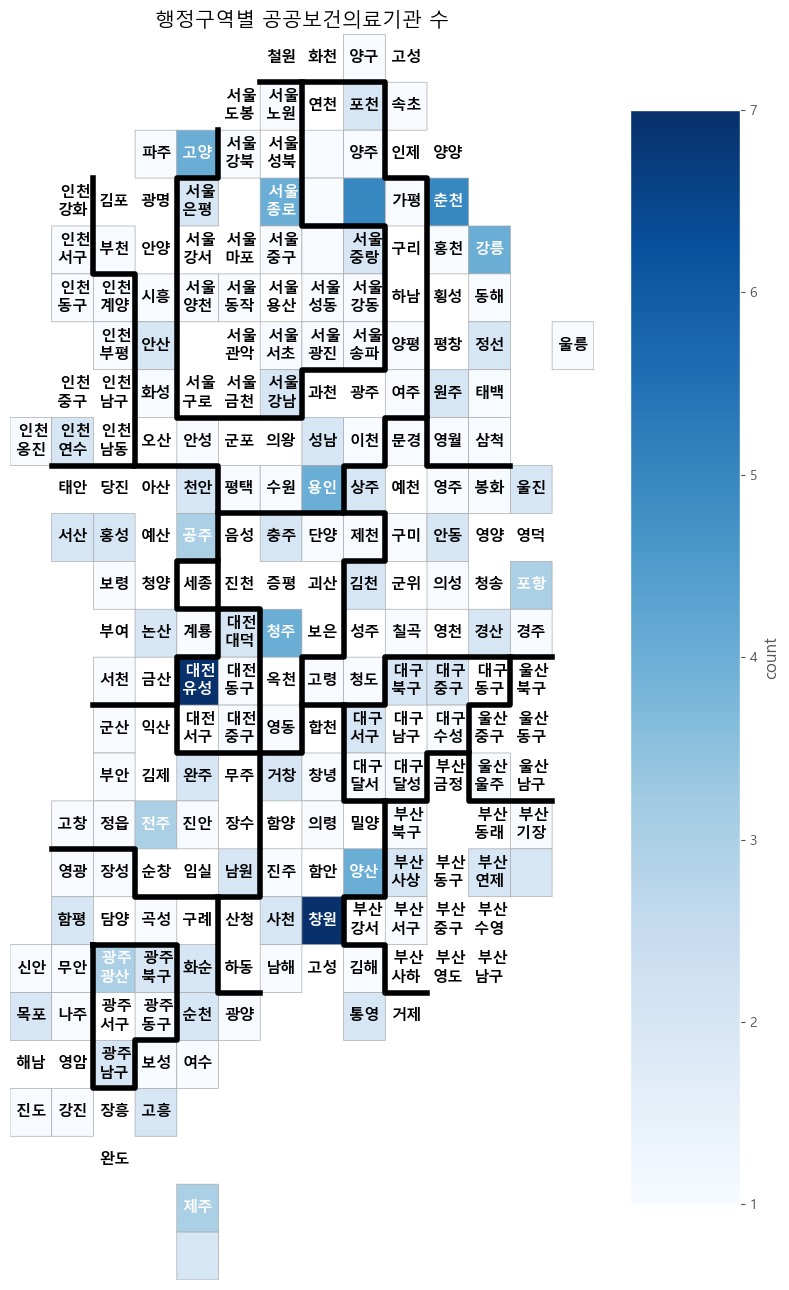

In [65]:
draw_blockMap(data_draw_korea_MC_Population_all, 'count', '행정구역별 공공보건의료기관 수', 'Blues')

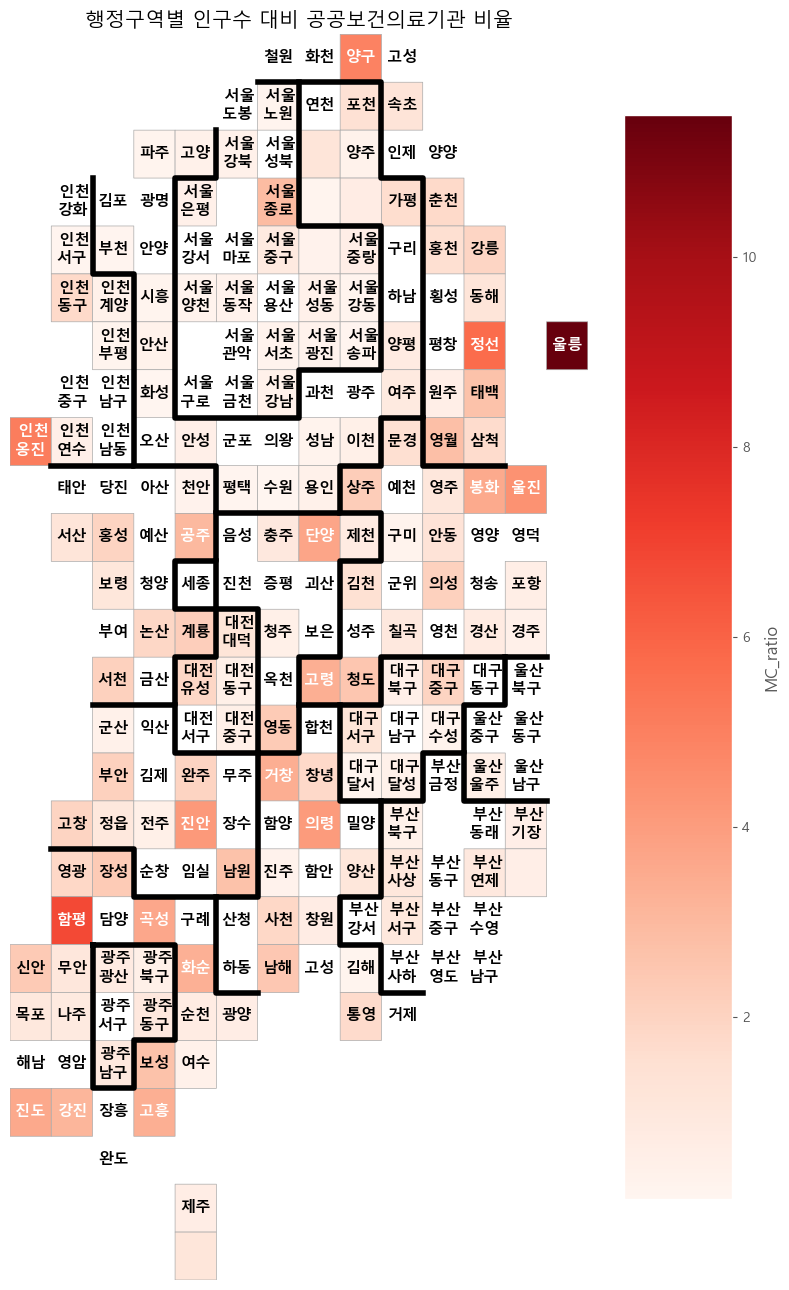

In [66]:
draw_blockMap( data_draw_korea_MC_Population_all, 'MC_ratio', '행정구역별 인구수 대비 공공보건의료기관 비율', 'Reds')

In [67]:
library = pd.read_csv('9장_data/NL_PUBLIC_LBRRY_PER_AVRG_POPLTN_CO_LIST_202105.csv')
library.head() #작업 확인용 출력

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,ONE_AREA_NM,TWO_AREA_NM,PUBLIC_LBRRY_CO,POPLTN_CO,AVRG_POPLTN_CO
0,2021,1,강원도,강릉시,4,213412,53353.00
1,2021,1,강원도,고성군,3,26687,8895.67
2,2021,1,강원도,동해시,3,90416,30138.67
3,2021,1,강원도,삼척시,3,64946,21648.67
4,2021,1,강원도,속초시,3,82652,27550.67


In [68]:
#컬럼명 변경
library = library.rename(columns = {'ONE_AREA_NM': '시도', 'TWO_AREA_NM': '군구', 'PUBLIC_LBRRY_CO': '도서관수'})
library['군구'] = library['군구'].str.strip()
library['시도군구'] = library.apply(lambda r: r['시도']+' '+r['군구'],axis = 1)
library.head(1)

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도,군구,도서관수,POPLTN_CO,AVRG_POPLTN_CO,시도군구
0,2021,1,강원도,강릉시,4,213412,53353.0,강원도 강릉시


In [69]:
# 주소에서 시도, 군구 정보 분리
addr = pd.DataFrame({'시도': library['시도'], '군구': library['군구'], '도서관수': library['도서관수'] })
addr.head() #작업 확인용 출력

,시도,군구,도서관수
0,강원도,강릉시,4
1,강원도,고성군,3
2,강원도,동해시,3
3,강원도,삼척시,3
4,강원도,속초시,3


In [70]:
addr['시도'].unique()
addr['군구'].unique()

array(['강릉시', '고성군', '동해시', '삼척시', '속초시', '양구군', '양양군', '영월군', '원주시',
       '인제군', '정선군', '철원군', '춘천시', '태백시', '평창군', '홍천군', '화천군', '횡성군',
       '가평군', '고양시 덕양구', '고양시 일산동구', '고양시 일산서구', '과천시', '광명시', '광주시',
       '구리시', '군포시', '김포시', '남양주시', '동두천시', '부천시', '성남시 분당구', '성남시 수정구',
       '성남시 중원구', '수원시 권선구', '수원시 영통구', '수원시 장안구', '수원시 팔달구', '시흥시',
       '안산시 단원구', '안산시 상록구', '안성시', '안양시 동안구', '안양시 만안구', '양주시', '양평군',
       '여주시', '연천군', '오산시', '용인시 기흥구', '용인시 수지구', '용인시 처인구', '의왕시',
       '의정부시', '이천시', '파주시', '평택시', '포천시', '하남시', '화성시', '거제시', '거창군',
       '김해시', '남해군', '밀양시', '사천시', '산청군', '양산시', '의령군', '진주시', '창녕군',
       '창원시 마산합포구', '창원시 마산회원구', '창원시 성산구', '창원시 의창구', '창원시 진해구', '통영시',
       '하동군', '함안군', '함양군', '합천군', '경산시', '경주시', '고령군', '구미시', '군위군',
       '김천시', '문경시', '봉화군', '상주시', '성주군', '안동시', '영덕군', '영양군', '영주시',
       '영천시', '예천군', '울릉군', '울진군', '의성군', '청도군', '청송군', '칠곡군', '포항시 남구',
       '포항시 북구', '광산구', '남구', '동구', '북구', '서구', '달서구', '달성군', '수성구', '중구',
      

In [71]:
addr['시도군구'] = addr.apply(lambda r: r['시도'] + ' ' + r['군구'], axis = 1)
addr['count'] = 0
addr.head()

,시도,군구,도서관수,시도군구,count
0,강원도,강릉시,4,강원도 강릉시,0
1,강원도,고성군,3,강원도 고성군,0
2,강원도,동해시,3,강원도 동해시,0
3,강원도,삼척시,3,강원도 삼척시,0
4,강원도,속초시,3,강원도 속초시,0


In [72]:
# as_index = False -> groupby는 그룹 컬럼을 인덱스로 삼는데 일반 인덱스를 사용하겠다는 의미
# addr = addr.reset_index(drop=True)
addr_group = pd.DataFrame( addr.groupby(['시도', '군구', '시도군구', '도서관수'], as_index = False).count())
addr_group.head(3) #작업 확인용 출력

,시도,군구,시도군구,도서관수,count
0,강원도,강릉시,강원도 강릉시,4,4
1,강원도,고성군,강원도 고성군,3,4
2,강원도,동해시,강원도 동해시,3,4


In [73]:
addr_group.head()

,시도,군구,시도군구,도서관수,count
0,강원도,강릉시,강원도 강릉시,4,4
1,강원도,고성군,강원도 고성군,3,4
2,강원도,동해시,강원도 동해시,3,4
3,강원도,삼척시,강원도 삼척시,3,4
4,강원도,속초시,강원도 속초시,3,4


In [74]:
library.head(1)

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도,군구,도서관수,POPLTN_CO,AVRG_POPLTN_CO,시도군구
0,2021,1,강원도,강릉시,4,213412,53353.0,강원도 강릉시


In [75]:
library = library.set_index("시도군구")
library.head(1)

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도,군구,도서관수,POPLTN_CO,AVRG_POPLTN_CO
시도군구,,,,,,,
강원도 강릉시,2021,1,강원도,강릉시,4,213412,53353.0


In [76]:
addr_library_merge = pd.merge(addr_group, library, how='inner', on='시도군구')
addr_library_merge.head()

,시도_x,군구_x,시도군구,도서관수_x,count,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도_y,군구_y,도서관수_y,POPLTN_CO,AVRG_POPLTN_CO
0,강원도,강릉시,강원도 강릉시,4,4,2021,1,강원도,강릉시,4,213412,53353.00
1,강원도,강릉시,강원도 강릉시,4,4,2021,2,강원도,강릉시,4,213231,53307.75
2,강원도,강릉시,강원도 강릉시,4,4,2021,3,강원도,강릉시,4,212909,53227.25
3,강원도,강릉시,강원도 강릉시,4,4,2021,4,강원도,강릉시,4,212890,53222.50
4,강원도,고성군,강원도 고성군,3,4,2021,1,강원도,고성군,3,26687,8895.67


In [77]:
addr_library_merge.columns

Index(['시도_x', '군구_x', '시도군구', '도서관수_x', 'count', 'ANALS_TRGET_YEAR',
       'ANALS_TRGET_MT', '시도_y', '군구_y', '도서관수_y', 'POPLTN_CO',
       'AVRG_POPLTN_CO'],
      dtype='object')

In [78]:
local_MC_library = addr_library_merge[['시도_x', '군구_x','도서관수_x', 'count', 'POPLTN_CO']]
local_MC_library.head(5) #작업 확인용 출력

,시도_x,군구_x,도서관수_x,count,POPLTN_CO
0,강원도,강릉시,4,4,213412
1,강원도,강릉시,4,4,213231
2,강원도,강릉시,4,4,212909
3,강원도,강릉시,4,4,212890
4,강원도,고성군,3,4,26687


In [79]:
local_MC_library = local_MC_library.rename(columns= {'시도_x' : '시도','군구_x' : '군구','도서관수_x': '도서관수', 'POPLTN_CO' : '인구수'})
lc_count = local_MC_library['count']
local_MC_library['MC_ratio'] = lc_count.div(local_MC_library['인구수'], axis = 0)*100000
local_MC_library.head(2)
local_MC_library['시도별']=local_MC_library.groupby('시도',as_index=False)['도서관수'].transform('mean')

In [80]:
local_MC_library.head(20)

,시도,군구,도서관수,count,인구수,MC_ratio,시도별
0,강원도,강릉시,4,4,213412,1.874309,3.277778
1,강원도,강릉시,4,4,213231,1.875900,3.277778
2,강원도,강릉시,4,4,212909,1.878737,3.277778
3,강원도,강릉시,4,4,212890,1.878905,3.277778
4,강원도,고성군,3,4,26687,14.988571,3.277778
5,강원도,고성군,3,4,26734,14.962220,3.277778
6,강원도,고성군,3,4,26743,14.957185,3.277778
7,강원도,고성군,3,4,26760,14.947683,3.277778
8,강원도,동해시,3,4,90416,4.423996,3.277778
9,강원도,동해시,3,4,90320,4.428698,3.277778


In [81]:
from matplotlib import pyplot as plt
from matplotlib import rcParams, style
style.use('ggplot')

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties( fname = "c:/Windows/Fonts/malgun.ttf").get_name()
rc('font', family = font_name)

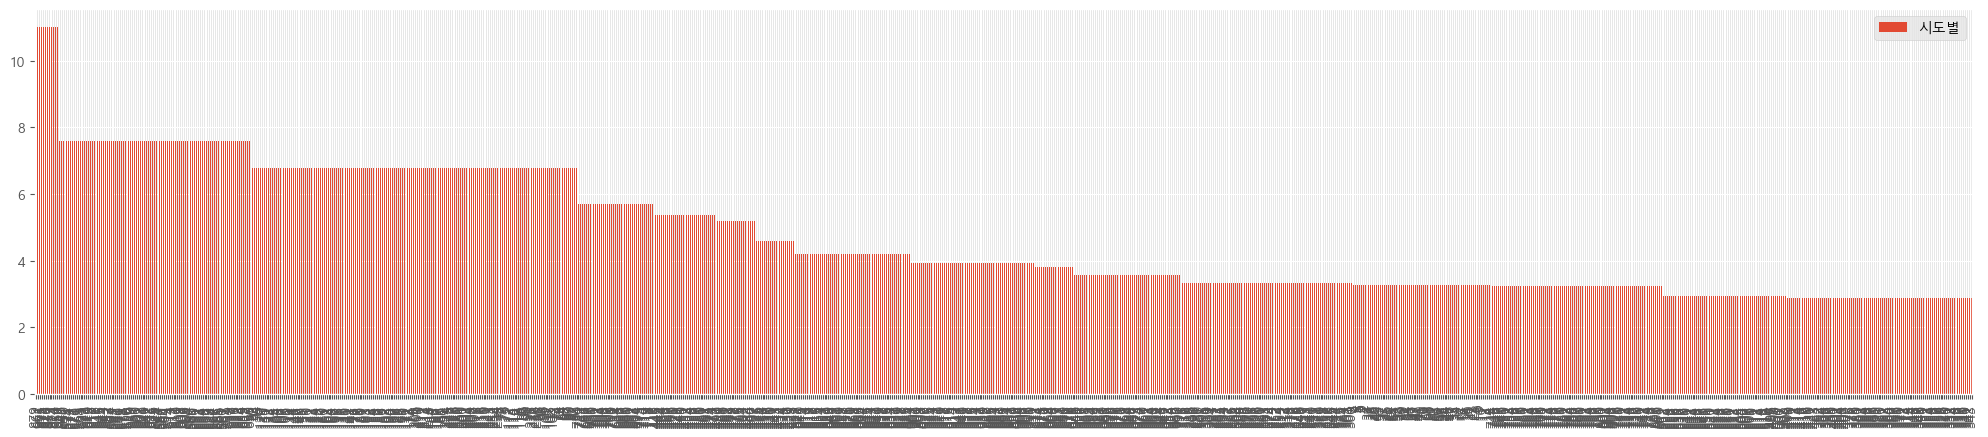

In [82]:

MC_ratio = local_MC_library[['시도별']]
MC_ratio = MC_ratio.sort_values('시도별', ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
MC_ratio.plot(kind = 'bar', rot = 90)
plt.show()

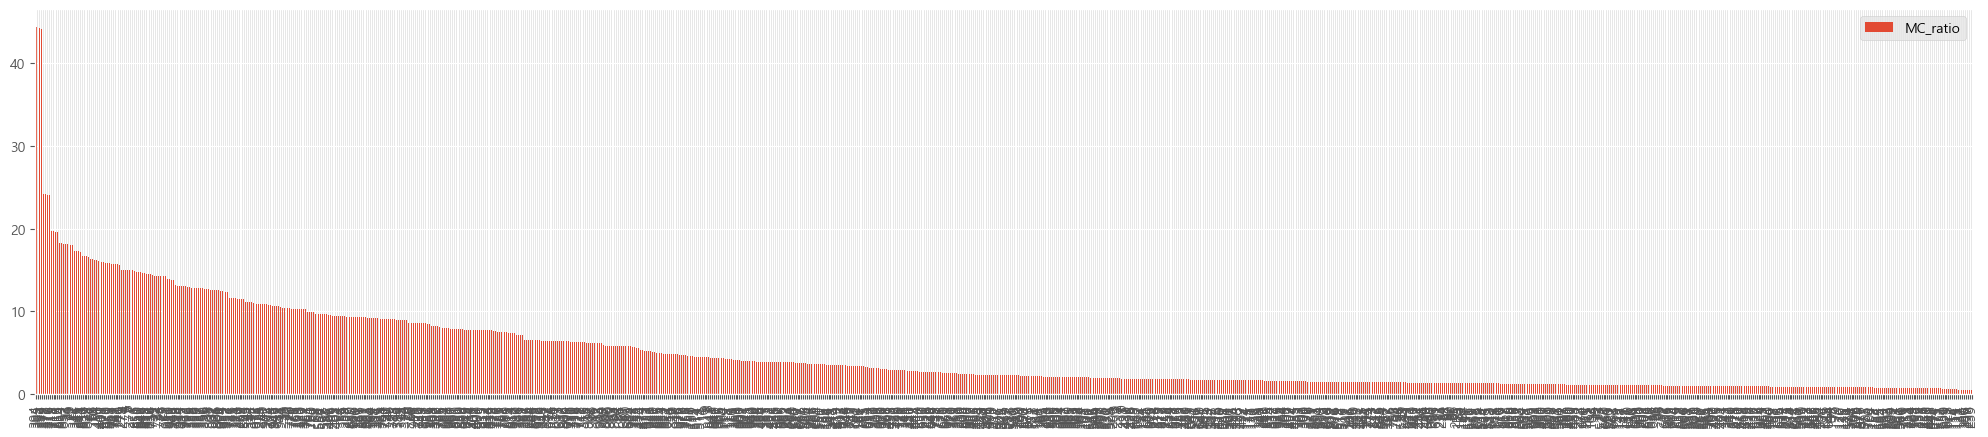

In [83]:
MC_ratio = local_MC_library[['MC_ratio']]
MC_ratio = MC_ratio.sort_values('MC_ratio', ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
MC_ratio.plot(kind = 'bar', rot = 90)
plt.show()

In [84]:
import os
path = os.getcwd()

In [85]:
data_draw_korea = pd.read_csv(path+'\\9장_data\\data_draw_korea.csv', index_col = 0, encoding = 'UTF-8', engine = 'python')
data_draw_korea.head(20) #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원도,강릉시
1,25589,고성(강원),9,0,664.19,강원도,고성군
2,86747,동해,11,5,180.01,강원도,동해시
3,63986,삼척,11,8,1185.80,강원도,삼척시
4,76733,속초,9,1,105.25,강원도,속초시
5,20809,양구,8,0,700.80,강원도,양구군
6,24551,양양,10,2,628.68,강원도,양양군
7,34966,영월,10,8,1127.36,강원도,영월군
8,313851,원주,10,7,867.30,강원도,원주시
9,29260,인제,9,2,1646.08,강원도,인제군


In [86]:
#2023년 6월 이후에 변경된 행정구역명으로 수정하기
addr_aliases = { '강원도':'강원특별자치도', '전라북도':'전북특별자치도'}
data_draw_korea['광역시도'] = data_draw_korea['광역시도'].apply(lambda v: addr_aliases.get(v, v))
data_draw_korea.head() #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
1,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
2,86747,동해,11,5,180.01,강원특별자치도,동해시
3,63986,삼척,11,8,1185.80,강원특별자치도,삼척시
4,76733,속초,9,1,105.25,강원특별자치도,속초시


In [87]:
data_draw_korea['시도군구'] = data_draw_korea.apply(lambda r: r['광역시도'] + ' ' + r['행정구역'], axis = 1)

In [88]:
data_draw_korea = data_draw_korea.set_index("시도군구")

data_draw_korea.head() #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
시도군구,,,,,,,
강원특별자치도 강릉시,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
강원특별자치도 고성군,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
강원특별자치도 동해시,86747,동해,11,5,180.01,강원특별자치도,동해시
강원특별자치도 삼척시,63986,삼척,11,8,1185.80,강원특별자치도,삼척시
강원특별자치도 속초시,76733,속초,9,1,105.25,강원특별자치도,속초시


In [89]:
local_MC_library.head(10)

,시도,군구,도서관수,count,인구수,MC_ratio,시도별
0,강원도,강릉시,4,4,213412,1.874309,3.277778
1,강원도,강릉시,4,4,213231,1.875900,3.277778
2,강원도,강릉시,4,4,212909,1.878737,3.277778
3,강원도,강릉시,4,4,212890,1.878905,3.277778
4,강원도,고성군,3,4,26687,14.988571,3.277778
5,강원도,고성군,3,4,26734,14.962220,3.277778
6,강원도,고성군,3,4,26743,14.957185,3.277778
7,강원도,고성군,3,4,26760,14.947683,3.277778
8,강원도,동해시,3,4,90416,4.423996,3.277778
9,강원도,동해시,3,4,90320,4.428698,3.277778


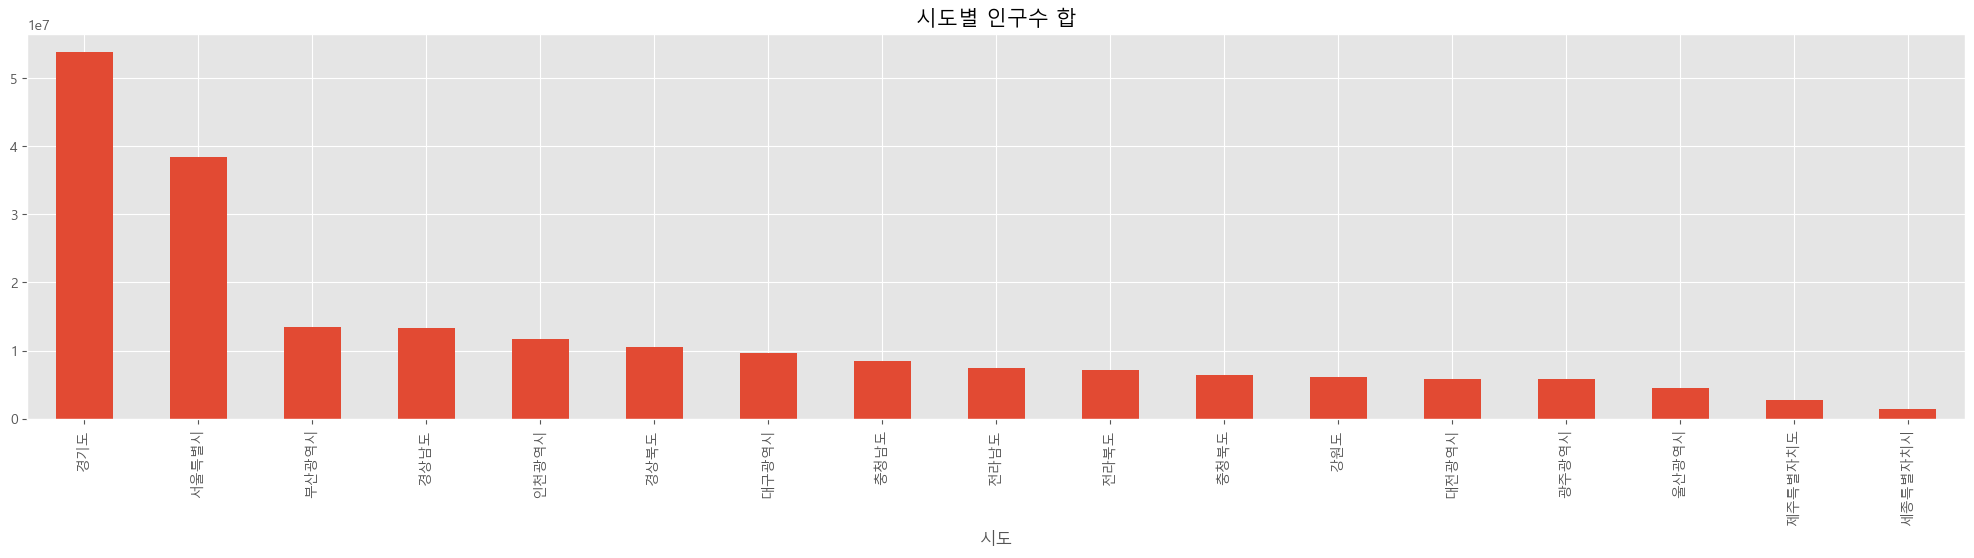

In [90]:
new_library = local_MC_library.groupby('시도')['인구수'].sum()
new_library = new_library.sort_values(ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
new_library.plot(kind = 'bar', rot = 90)
plt.title('시도별 인구수 합', fontsize=15)
plt.show()

In [91]:
local_MC_library.groupby('시도')[['도서관수','인구수']].sum().sort_values('도서관수',ascending=False)


,도서관수,인구수
시도,,
경기도,1140,53866892
서울특별시,760,38493770
경상남도,292,13334527
전라남도,284,7389329
경상북도,276,10545845
충청남도,252,8471654
전라북도,252,7197848
강원도,236,6155145
인천광역시,228,11756832


In [92]:
local_MC_library.groupby('시도')[['도서관수','인구수']].sum().sort_values('인구수',ascending=False)


,도서관수,인구수
시도,,
경기도,1140,53866892
서울특별시,760,38493770
부산광역시,188,13519252
경상남도,292,13334527
인천광역시,228,11756832
경상북도,276,10545845
대구광역시,172,9644175
충청남도,252,8471654
전라남도,284,7389329


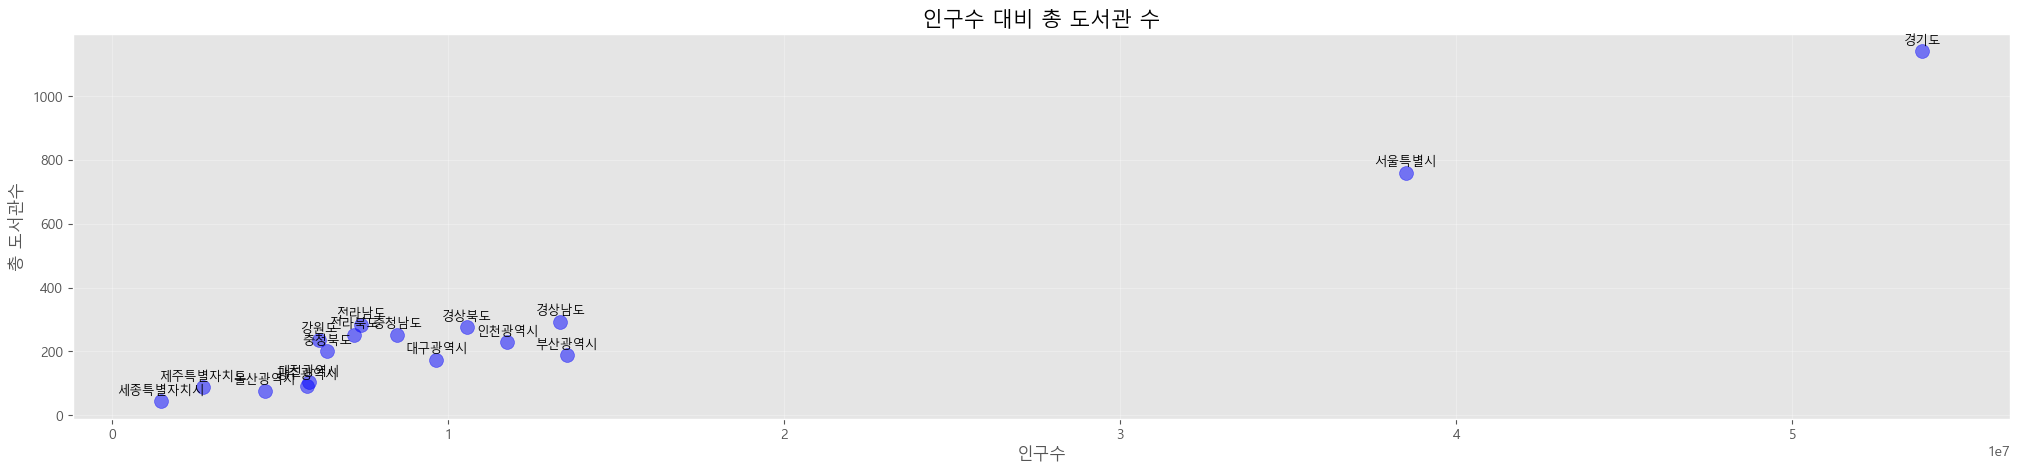

In [93]:
scatter_library = local_MC_library.groupby('시도')[['인구수','도서관수']].sum().reset_index()
plt.scatter(scatter_library['인구수'], scatter_library['도서관수'], s=100, color='blue', alpha=0.5)
plt.rcParams["figure.figsize"] = (25, 5)
for i, txt in enumerate(scatter_library['시도']):
    offset = scatter_library['도서관수'].max() * 0.02
    plt.text(scatter_library['인구수'].iloc[i], scatter_library['도서관수'].iloc[i] + offset, 
             txt, fontsize=9, ha='center', color='black')
plt.title('인구수 대비 총 도서관 수', fontsize=15)
plt.xlabel('인구수', fontsize=12)
plt.ylabel('총 도서관수', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

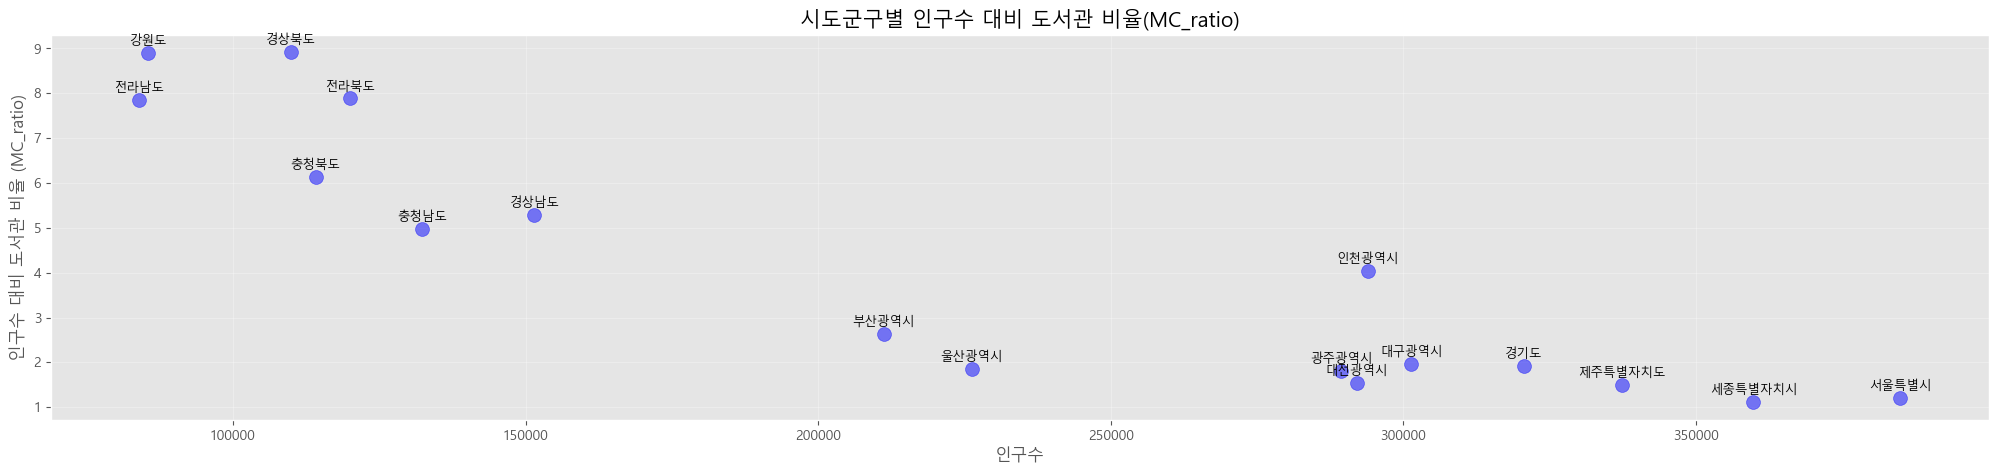

In [94]:
scatter_library = local_MC_library.groupby('시도')[['인구수','MC_ratio']].mean().reset_index()
plt.scatter(scatter_library['인구수'], scatter_library['MC_ratio'], s=100, color='blue', alpha=0.5)
plt.rcParams["figure.figsize"] = (25, 5)
for i, txt in enumerate(scatter_library['시도']):
    offset = scatter_library['MC_ratio'].max() * 0.02
    plt.text(scatter_library['인구수'].iloc[i], scatter_library['MC_ratio'].iloc[i] + offset, 
             txt, fontsize=9, ha='center', color='black')
plt.title('시도군구별 인구수 대비 도서관 비율(MC_ratio)', fontsize=15)
plt.xlabel('인구수', fontsize=12)
plt.ylabel('인구수 대비 도서관 비율 (MC_ratio)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

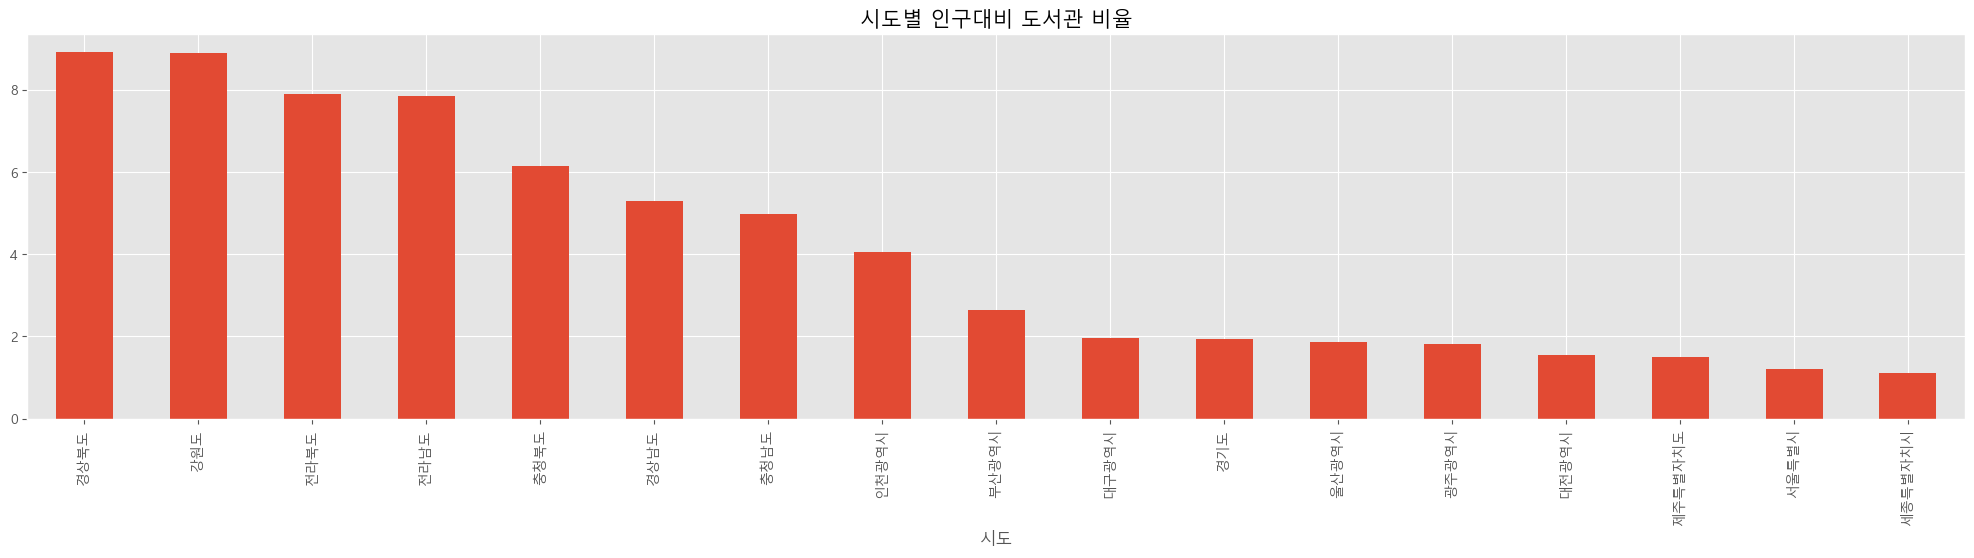

In [95]:
new_library = local_MC_library.groupby('시도')['MC_ratio'].mean()
new_library.head(2)
new_library = new_library.sort_values(ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
new_library.plot(kind = 'bar', rot = 90)
plt.title('시도별 인구대비 도서관 비율', fontsize=15)
plt.show()

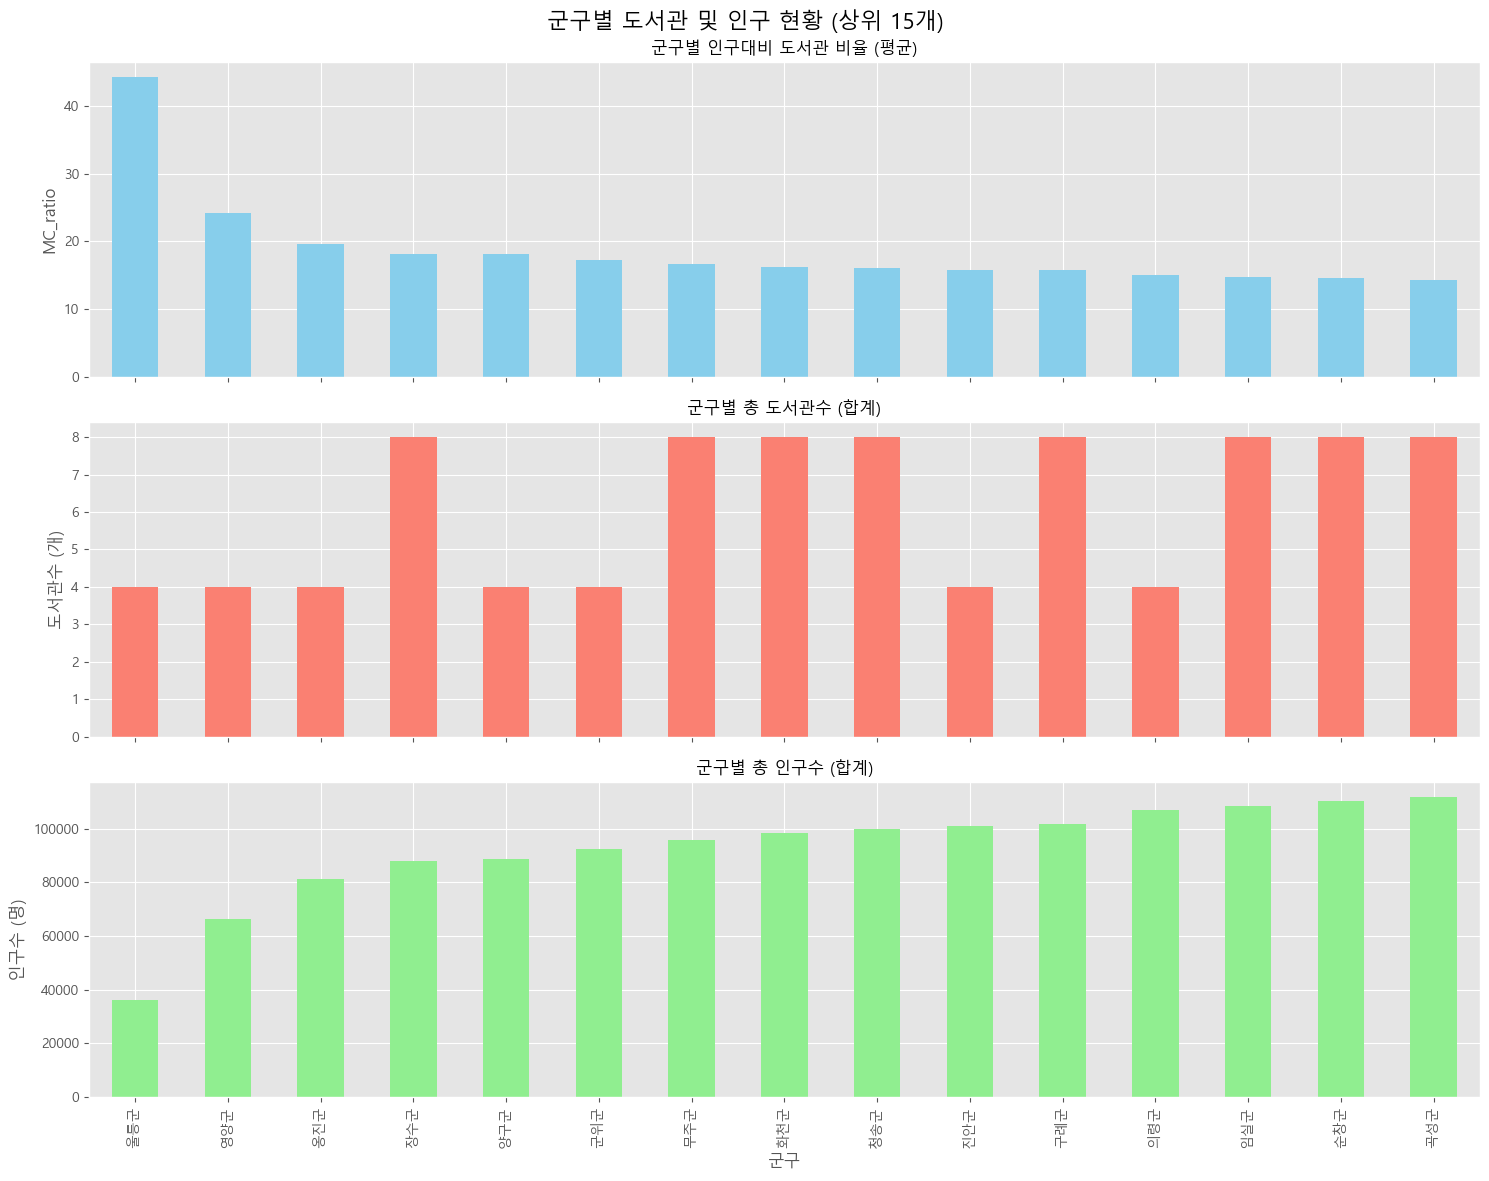

In [ ]:
new_library = local_MC_library.groupby('군구').agg({
    '인구수': 'sum',
    '도서관수': 'sum',
    'MC_ratio': 'mean'
})

new_library = new_library.sort_values('MC_ratio', ascending=False).head(15)


fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

new_library['MC_ratio'].plot(kind='bar', ax=axes[0], color='skyblue', rot=90)
axes[0].set_title('군구별 인구대비 도서관 비율 (평균)', fontsize=12)
axes[0].set_ylabel('MC_ratio')

new_library['도서관수'].plot(kind='bar', ax=axes[1], color='salmon', rot=90)
axes[1].set_title('군구별 총 도서관수 (합계)', fontsize=12)
axes[1].set_ylabel('도서관수 (개)')


new_library['인구수'].plot(kind='bar', ax=axes[2], color='lightgreen', rot=90)
axes[2].set_title('군구별 총 인구수 (합계)', fontsize=12)
axes[2].set_ylabel('인구수 (명)')


plt.suptitle('군구별 도서관 및 인구 현황 (상위 15개)', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
data_draw_korea_MC_library_all = pd.merge(data_draw_korea,local_MC_library, how = 'outer', 
                                             left_on='행정구역', right_on = '군구')
data_draw_korea_MC_library_all.head(10)

,인구수_x,shortName,x,y,면적,광역시도,행정구역,시도,군구,도서관수,count,인구수_y,MC_ratio,시도별
0,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62399.0,6.410359,6.785714
1,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62339.0,6.416529,6.785714
2,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62049.0,6.446518,6.785714
3,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62206.0,6.430248,6.785714
4,526157.0,서울강남,6.0,7.0,39.50,서울특별시,강남구,서울특별시,강남구,14.0,4.0,538536.0,0.742754,7.600000
5,526157.0,서울강남,6.0,7.0,39.50,서울특별시,강남구,서울특별시,강남구,14.0,4.0,537879.0,0.743662,7.600000
6,526157.0,서울강남,6.0,7.0,39.50,서울특별시,강남구,서울특별시,강남구,14.0,4.0,534796.0,0.747949,7.600000
7,526157.0,서울강남,6.0,7.0,39.50,서울특별시,강남구,서울특별시,강남구,14.0,4.0,533579.0,0.749655,7.600000
8,432028.0,서울강동,8.0,5.0,24.60,서울특별시,강동구,서울특별시,강동구,9.0,4.0,461334.0,0.867051,7.600000
9,432028.0,서울강동,8.0,5.0,24.60,서울특별시,강동구,서울특별시,강동구,9.0,4.0,464208.0,0.861683,7.600000


In [ ]:
BORDER_LINES = [
    [(3, 2), (5, 2), (5, 3), (9, 3), (9, 1)], # 인천
    [ (2, 5), (3, 5), (3, 4), (8, 4), (8, 7), (7, 7), (7, 9), (4, 9),
    (4, 7), (1, 7)], # 서울
    [(1, 6), (1, 9), (3, 9), (3, 10), (8, 10), (8, 9),
    (9, 9), (9, 8), (10, 8), (10, 5), (9, 5), (9, 3)], # 경기도
    [(9, 12), (9, 10), (8, 10)], # 강원도
    [(10, 5), (11, 5), (11, 4), (12, 4), (12, 5), (13, 5),
    (13, 4), (14, 4), (14, 2)], # 충청남도
    [(11, 5), (12, 5), (12, 6), (15, 6), (15, 7), (13, 7),
    (13, 8), (11, 8), (11, 9), (10, 9), (10, 8)], # 충청북도
    [(14, 4), (15, 4), (15, 6)], # 대전시
    [(14, 7), (14, 9), (13, 9), (13, 11), (13, 13)], # 경상북도
    [(14, 8), (16, 8), (16, 10), (15, 10),
    (15, 11), (14, 11), (14, 12), (13, 12)], # 대구시
    [(15, 11), (16, 11), (16, 13)], # 울산시
    [(17, 1), (17, 3), (18, 3), (18, 6), (15, 6)], # 전라북도
    [ (19, 2), (19, 4), (21, 4), (21, 3), (22, 3), (22, 2), (19, 2)], #광주시
    [(18, 5), (20, 5), (20, 6)], # 전라남도
    [ (16, 9), (18, 9), (18, 8), (19, 8), (19, 9), (20, 9), (20, 10)], #부산시
]

In [ ]:
def draw_blockMap(blockedMap, targetData, title, color):
    whitelabelmin = ( max(blockedMap[targetData]) - min(blockedMap[targetData])) * 0.25 + min(blockedMap[targetData])
    datalabel = targetData
    vmin = min(blockedMap[targetData])
    vmax = max(blockedMap[targetData])
    mapdata = blockedMap.pivot(index = 'y', columns = 'x', values = targetData)
    masked_mapdata = np.ma.masked_where(np.isnan(mapdata), mapdata)
    
    plt.figure(figsize = (8, 13))
    plt.title(title)
    plt.pcolor( masked_mapdata, vmin = vmin, vmax = vmax, cmap = color, edgecolor = '#aaaaaa', linewidth = 0.5)
    #지역 이름 표시
    for idx, row in blockedMap.iterrows():
        annocolor = 'white' if row[targetData] > whitelabelmin else 'black'
        #광역시는 구 이름이 겹치는 경우가 많아서 시단위 이름도 같이 표시
        if row['광역시도'].endswith('시') and not row['광역시도'].startswith('세종'):
            dispname = ' {}\n{}'.format(row['광역시도'][:2], row['행정구역'][:-1])
            if len(row['행정구역']) <= 2:
                dispname += row['행정구역'][-1]
        else:
            dispname = row['행정구역'][:-1]
            
        #서대문구, 서귀포시 같이 이름이 3자 이상이면 작은 글자로 표시
        if len(dispname.splitlines()[-1]) >= 3:
            fontsize, linespacing = 9.5, 1.5
        else:
            fontsize, linespacing = 11, 1.2
            
            plt.annotate(dispname, (row['x']+0.5, row['y']+0.5), weight = 'bold',fontsize = fontsize, 
                         ha = 'center', va = 'center', color = annocolor, linespacing = linespacing)

    #시도 경계를 그린다.
    for path in BORDER_LINES:
        ys, xs = zip(*path)
        plt.plot(xs, ys, c = 'black', lw = 4)
        
    plt.gca().invert_yaxis()
    #plt.gca().set_aspect(1)
    plt.axis('off')
    
    cb = plt.colorbar(shrink = 1, aspect = 10)
    cb.set_label(datalabel)
    
    plt.tight_layout()
    plt.savefig('.\\9장_data\\' + 'blockMap_' + targetData + '.png')
    plt.show()

C:\Users\pc888\AppData\Local\Temp\ipykernel_11536\1460417458.py:41: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  cb = plt.colorbar(shrink = 1, aspect = 10)


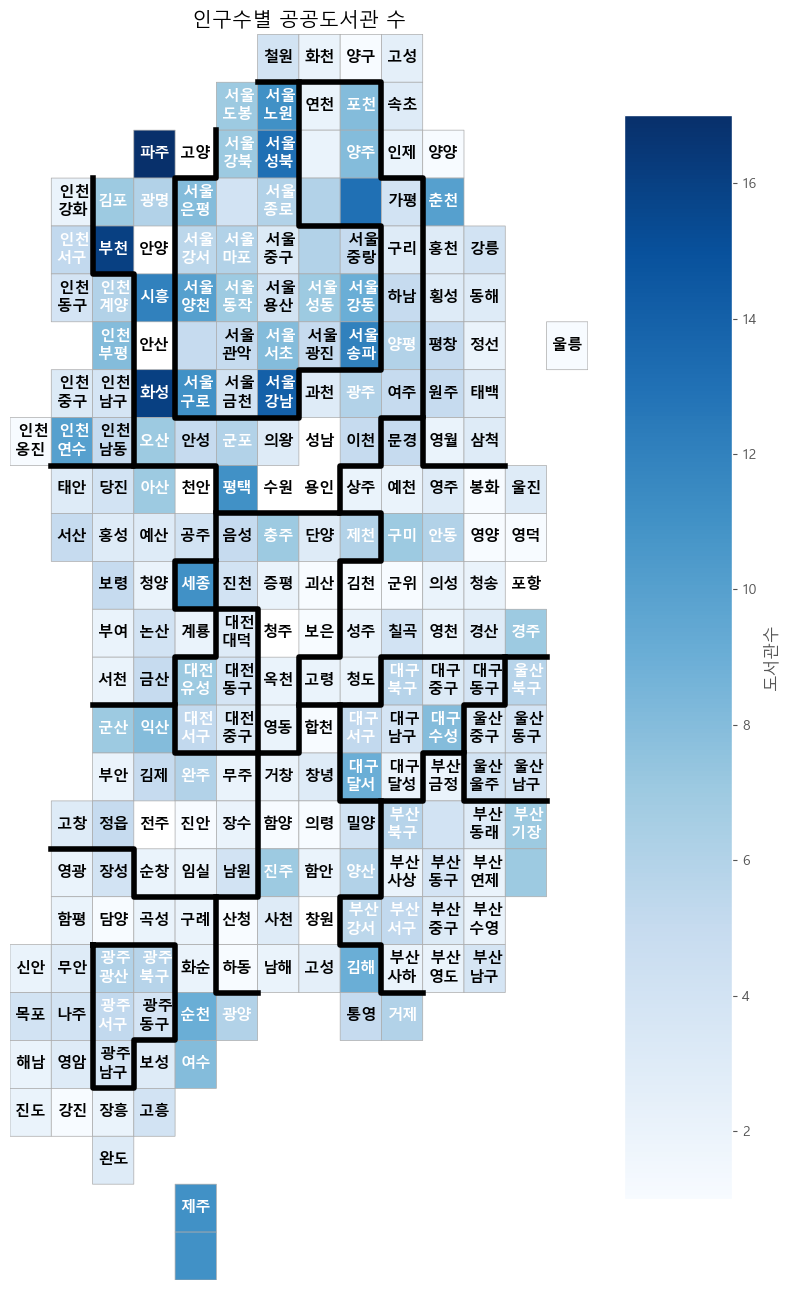

In [ ]:
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.reset_index().groupby(['x', 'y', '광역시도', '행정구역'], as_index=False)['도서관수'].mean(numeric_only=True)
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.dropna(subset=['x', 'y'])
draw_blockMap(data_draw_korea_MC_library_all, '도서관수', '인구수별 공공도서관 수', 'Blues')

C:\Users\pc888\AppData\Local\Temp\ipykernel_11536\1460417458.py:41: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  cb = plt.colorbar(shrink = 1, aspect = 10)


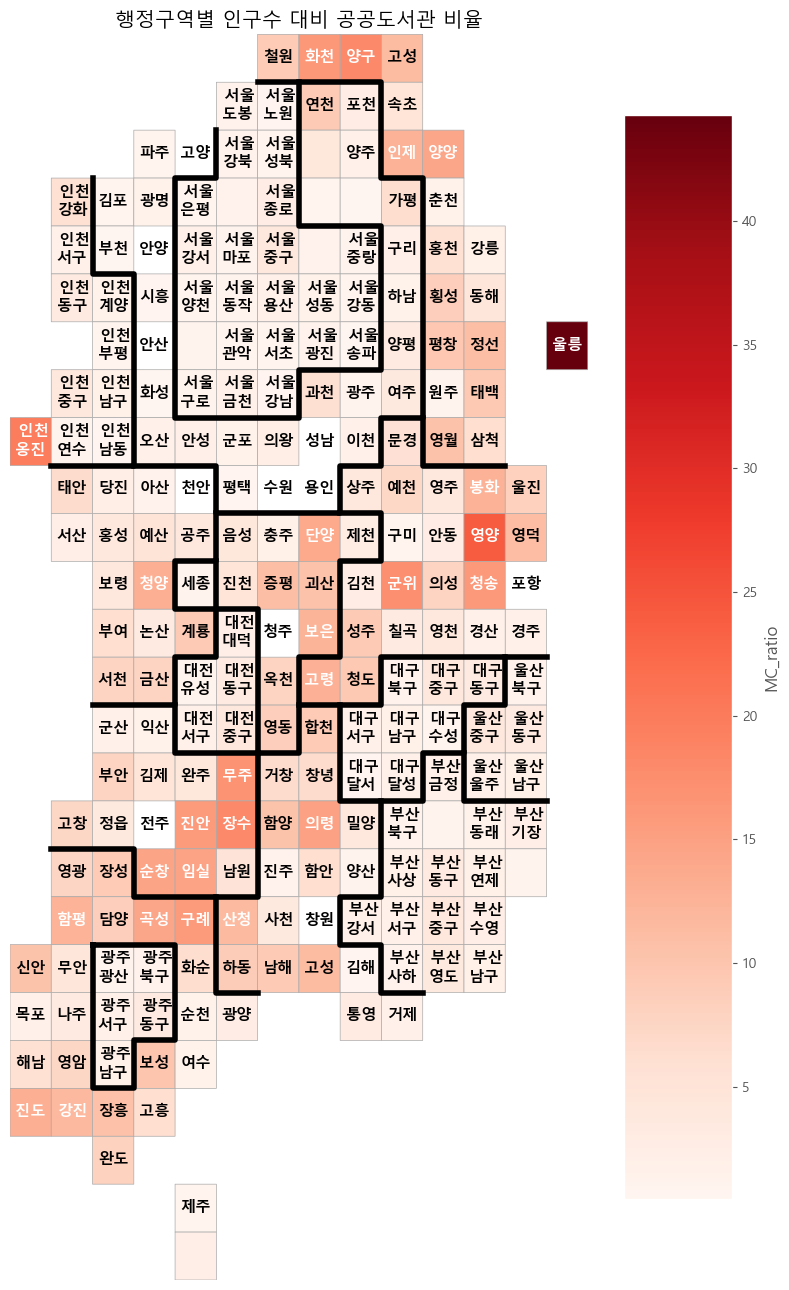

In [ ]:
data_draw_korea_MC_library_all = pd.merge(data_draw_korea,local_MC_library, how = 'outer', 
                                             left_on='행정구역', right_on = '군구')
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.reset_index().groupby(['x', 'y', '광역시도', '행정구역'], as_index=False)['MC_ratio'].mean(numeric_only=True)
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.dropna(subset=['x', 'y'])
draw_blockMap( data_draw_korea_MC_library_all, 'MC_ratio', '행정구역별 인구수 대비 공공도서관 비율', 'Reds')